# CFB-GBM Survival EDA

A standalone notebook for inspecting the supplied CFB-GBM TSV files, validating the survival outcome, exploring baseline clinical and radiomic features, auditing leakage, and exporting a patient-level dataset and analysis artifacts. All analysis logic is defined in notebook cells; no companion Python script is required.

**Important:** the supplied dictionary defines the outcome as weeks from t0 MRI to death; no independent censoring/status field is supplied. Interpret survival curves and associations as descriptive for these records, not as population survival estimates.

## 1. Environment setup and imports
Import analysis, plotting, and utility packages.

## 2. Notebook configuration and paths
Resolve the workspace from the data directory, configure reproducibility, and set output locations.

In [13]:
# Standalone environment, imports, paths, and reproducibility configuration.
from pathlib import Path
import re
import warnings

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data").is_dir()), Path.cwd())
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs" / "eda"
TABLE_DIR = OUT_DIR / "tables"
FIGURE_DIR = OUT_DIR / "figures"
REPORT_PATH = OUT_DIR / "eda_report.md"
ID_COLUMN = "id_patient"
SURVIVAL_COLUMN = "survival (weeks)"
RAD_PREFIX = "original_"
SEED = 20261010

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Image

np.random.seed(SEED)
warnings.filterwarnings("ignore", category=RuntimeWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Remove stale generated files so reruns cannot leave obsolete artifacts.
for folder in (TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
for pattern, folder in (("*.csv", TABLE_DIR), ("*.txt", TABLE_DIR), ("*.png", FIGURE_DIR)):
    for old_file in folder.glob(pattern):
        old_file.unlink()

# Parsing and naming helpers used directly by later notebook cells.
def read_tsv(path: Path) -> pd.DataFrame:
    return pd.read_csv(path, sep="\t", dtype={"id_patient": "string", "Patient": "string"}, low_memory=False)

def normalize_id(values: pd.Series) -> pd.Series:
    return values.astype("string").str.strip().str.replace(r"\.0$", "", regex=True)

def id_column(frame: pd.DataFrame) -> str | None:
    return next((c for c in ("id_patient", "Patient", "patient") if c in frame.columns), None)

def timepoint_column(frame: pd.DataFrame) -> str | None:
    return next((c for c in ("temporality", "Temporality", "timepoint", "Timepoint") if c in frame.columns), None)

def safe_name(value: str) -> str:
    return re.sub(r"[^A-Za-z0-9_-]+", "_", value).strip("_").lower()[:100]

def save_figure(fig: plt.Figure, filename: str) -> None:
    fig.tight_layout()
    fig.savefig(FIGURE_DIR / filename, bbox_inches="tight")
    plt.close(fig)

print(f"Workspace: {ROOT}")
print(f"Inputs: {DATA_DIR}")
print(f"Outputs: {OUT_DIR}")

Workspace: /Users/chiho/Desktop/b-hackathon/biostats-hackathon
Inputs: /Users/chiho/Desktop/b-hackathon/biostats-hackathon/data
Outputs: /Users/chiho/Desktop/b-hackathon/biostats-hackathon/outputs/eda


## 3. Load raw data sources

Read the supplied column dictionary first, then load every data TSV with tab separation and patient identifiers preserved as text.

In [14]:
input_files = sorted(DATA_DIR.glob("*.tsv"))
dictionary_path = next((p for p in input_files if "column_descriptions" in p.name.lower()), None)
if dictionary_path is None:
    raise FileNotFoundError("The supplied column-description TSV was not found.")

dictionary = read_tsv(dictionary_path)
column_descriptions = {}
for _, row in dictionary.iterrows():
    column_name = str(row.get("Column2", "")).strip()
    description = str(row.get("Column3", "")).strip().replace("\n", " ")
    if column_name and column_name.lower() != "nan" and description.lower() != "nan":
        column_descriptions[column_name] = description

raw_tables = {path.name: read_tsv(path) for path in input_files if path != dictionary_path}
print(f"Loaded {len(raw_tables)} data tables and the dictionary ({len(input_files)} TSV files total).")
for filename, frame in raw_tables.items():
    print(f"{filename}: {frame.shape[0]:,} rows × {frame.shape[1]:,} columns")
display(dictionary.head(10))

Loaded 7 data tables and the dictionary (8 TSV files total).
CFB-GBM_clinical_data_v03_20260619.tsv: 264 rows × 8 columns
CFB-GBM_ct_availability_v02_20260129.tsv: 264 rows × 4 columns
CFB-GBM_mri_availability_v02_20260129.tsv: 554 rows × 11 columns
CFB-GBM_rano_criteria_v04_20260909.tsv: 165 rows × 10 columns
CFB-GBM_treatment_data_v02_20260129.tsv: 264 rows × 4 columns
CFB-GBM_treatment_imaging_availability_v03_20260619.tsv: 536 rows × 7 columns
CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv: 2,424 rows × 150 columns


,Column1,Column2,Column3
0,source filename,columns,description
1,clinical_data.tsv\r\ntreatment_data.tsv\r\ntre...,id_patient,Unique patient number in the database.
2,clinical_data.tsv,survival (weeks),Time difference (in weeks) between the patient...
3,clinical_data.tsv,age_at_t0 (years),Age of the patient (in years) at t0.
4,clinical_data.tsv,who_performance_status,Represent the World Health Organization perfor...
5,clinical_data.csv,who_guideline,Indicate which WHO guideline was used:\r\n- 20...
6,clinical_data.tsv,gender,Patient's gender category: \r\n- F: Female;\r\...
7,clinical_data.tsv,height (cm),Patient's standing height (cm) at t0.
8,clinical_data.tsv,weight (kg),Patient's body weight (kg) at t0.
9,treatment_data.tsv,delay_t0_to_radiotherapy (weeks),Time difference (in weeks) between the gliobla...


## 4. Raw data inspection and schema checks

Review file shapes, schemas, missingness, duplicate rows, identifier counts, and safe first-ten-row previews. Patient IDs and scan filenames are omitted from displayed samples.

In [15]:
inventory_preview = []
for filename, frame in raw_tables.items():
    patient_column = id_column(frame)
    patient_ids = normalize_id(frame[patient_column]) if patient_column else pd.Series(dtype="string")
    inventory_preview.append({
        "file": filename,
        "rows": len(frame),
        "columns": len(frame.columns),
        "unique_patients": patient_ids.nunique(dropna=True) if patient_column else np.nan,
        "duplicate_rows": int(frame.duplicated().sum()),
        "missing_cells": int(frame.isna().sum().sum()),
        "missing_percent": float(frame.isna().sum().sum() / frame.size * 100) if frame.size else 0.0,
        "column_names": ", ".join(map(str, frame.columns)),
    })
display(pd.DataFrame(inventory_preview))

identifier_fields = ("id_patient", "Patient", "patient", "Image", "Mask")
for filename, frame in raw_tables.items():
    if "features_extraction" in filename:
        feature_columns = [c for c in frame if c.startswith(RAD_PREFIX)][:8]
        preview_columns = [c for c in ("Temporality", "Label name", "Sequence") if c in frame] + feature_columns
        preview = frame[preview_columns]
    else:
        preview = frame.drop(columns=[c for c in identifier_fields if c in frame], errors="ignore")
    print(f"\n{filename} — first 10 rows (identifying fields omitted)")
    display(preview.head(10).iloc[:, :12])

,file,rows,columns,unique_patients,duplicate_rows,missing_cells,missing_percent,column_names
0,CFB-GBM_clinical_data_v03_20260619.tsv,264,8,264,0,1,0.047348,"id_patient, survival (weeks), age_at_t0 (years..."
1,CFB-GBM_ct_availability_v02_20260129.tsv,264,4,264,0,69,6.534091,"id_patient, temporality, ct, ct_machine"
2,CFB-GBM_mri_availability_v02_20260129.tsv,554,11,264,0,0,0.000000,"id_patient, temporality, time_diff_t0 (weeks),..."
3,CFB-GBM_rano_criteria_v04_20260909.tsv,165,10,165,0,290,17.575758,"id_patient, size_t0 (cm3), size_t1 (cm3), size..."
4,CFB-GBM_treatment_data_v02_20260129.tsv,264,4,264,0,210,19.886364,"id_patient, delay_t0_to_radiotherapy (weeks), ..."
5,CFB-GBM_treatment_imaging_availability_v03_202...,536,7,264,0,687,18.310235,"id_patient, temporality, gtv, gtv_type, rtdose..."
6,CFB_GBM_features_extraction_pyradiomics_v03_20...,2424,150,261,0,0,0.000000,"Patient, Temporality, Image, Mask, Label name,..."



CFB-GBM_clinical_data_v03_20260619.tsv — first 10 rows (identifying fields omitted)


,survival (weeks),age_at_t0 (years),who_performance_status,who_guideline,gender,height (cm),weight (kg)
0,30,75,0.0,2016,F,152,49.0
1,43,75,2.0,2016,M,177,86.0
2,29,75,2.0,2016,F,165,75.0
3,40,70,1.0,2016,M,180,74.0
4,70,70,1.0,2016,F,164,69.0
5,130,60,1.0,2016,M,181,75.0
6,109,75,1.0,2016,M,173,91.0
7,66,60,1.0,2016,F,165,84.0
8,42,65,0.0,2016,F,167,45.0
9,66,75,1.0,2016,M,178,90.0



CFB-GBM_ct_availability_v02_20260129.tsv — first 10 rows (identifying fields omitted)


,temporality,ct,ct_machine
0,t0,1,BIGBORE
1,t0,1,BIGBORE
2,t0,1,BIGBORE
3,t0,1,BIGBORE
4,t0,1,BIGBORE
5,t0,1,BIGBORE
6,t0,1,BIGBORE
7,t0,1,BIGBORE
8,t0,1,BIGBORE
9,t0,1,BIGBORE


...

,delay_t0_to_radiotherapy (weeks),dose (Gy),fractions_number
0,1.0,40.05,15.0
1,3.0,60.00,30.0
2,0.0,40.05,15.0
3,1.0,60.00,30.0
4,1.0,60.00,30.0
5,3.0,60.00,30.0
6,1.0,60.00,30.0
7,2.0,60.00,30.0
8,1.0,40.05,15.0
9,1.0,60.00,30.0



CFB-GBM_treatment_imaging_availability_v03_20260619.tsv — first 10 rows (identifying fields omitted)


,temporality,gtv,gtv_type,rtdose,treatment_machine,tps
0,t0,1,humanSegmentation,1,T1,PRECISION
1,t0,1,humanSegmentation,1,T1,PRECISION
2,t0,1,humanSegmentation,1,RA2,ECLIPSE
3,t1,1,genSegmentation,0,NaN,NaN
4,t0,1,humanSegmentation,1,T2,PRECISION
5,t0,1,humanSegmentation,1,RA1,ECLIPSE
6,t1,1,genSegmentation,0,NaN,NaN
7,t2,1,genSegmentation,0,NaN,NaN
8,t0,1,humanSegmentation,1,RA1,RS
9,t1,1,genSegmentation,0,NaN,NaN



CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv — first 10 rows (identifying fields omitted)


,Temporality,Label name,Sequence,original_shape_Elongation,original_shape_Flatness,original_shape_LeastAxisLength,original_shape_MajorAxisLength,original_shape_Maximum2DDiameterColumn,original_shape_Maximum2DDiameterRow,original_shape_Maximum2DDiameterSlice,original_shape_Maximum3DDiameter
0,t0,GTV,t1gd,0.846321,0.686516,30.269951,44.092159,52.773099,52.773099,53.150729,55.596762
1,t0,GTV,adc,0.846321,0.686516,30.269951,44.092159,52.773099,52.773099,53.150729,55.596762
2,t0,GTV,flair,0.846321,0.686516,30.269951,44.092159,52.773099,52.773099,53.150729,55.596762
3,t0,GTV,t1eg,0.846321,0.686516,30.269951,44.092159,52.773099,52.773099,53.150729,55.596762
4,t0,GTV,t2star,0.846321,0.686516,30.269951,44.092159,52.773099,52.773099,53.150729,55.596762
5,t0,GTV,t1gd,0.571616,0.478438,28.824719,60.247546,42.107007,77.278716,73.109507,77.285186
6,t0,GTV,adc,0.571616,0.478438,28.824719,60.247546,42.107007,77.278716,73.109507,77.285186
7,t0,GTV,t2star,0.571616,0.478438,28.824719,60.247546,42.107007,77.278716,73.109507,77.285186
8,t0,GTV,t2tse,0.571616,0.478438,28.824719,60.247546,42.107007,77.278716,73.109507,77.285186
9,t0,GTV,t1gd,0.893517,0.775586,34.134487,44.011198,46.097722,51.400389,51.351728,52.877216


## 5. Data cleaning and type handling

Normalize patient IDs, coerce the defined survival duration to numeric, verify one clinical row per patient, and flag missing or invalid durations. No observations are removed automatically.

In [16]:
clinical_name = next(name for name in raw_tables if "clinical_data" in name.lower())
clinical = raw_tables[clinical_name].copy()
if ID_COLUMN not in clinical or SURVIVAL_COLUMN not in clinical:
    raise ValueError("Clinical table is missing its documented identifier or survival column.")
clinical[ID_COLUMN] = normalize_id(clinical[ID_COLUMN])
clinical[SURVIVAL_COLUMN] = pd.to_numeric(clinical[SURVIVAL_COLUMN], errors="coerce")
assert not clinical[ID_COLUMN].duplicated().any(), "Clinical table must have one row per patient."

outcome = clinical[SURVIVAL_COLUMN]
print({
    "patients": len(clinical),
    "missing_duration": int(outcome.isna().sum()),
    "zero_duration": int((outcome == 0).sum()),
    "negative_duration": int((outcome < 0).sum()),
    "unique_patient_ids": int(clinical[ID_COLUMN].nunique()),
})
for filename, frame in raw_tables.items():
    time_col = timepoint_column(frame)
    if time_col:
        print(filename, frame[time_col].value_counts(dropna=False).to_dict())

{'patients': 264, 'missing_duration': 0, 'zero_duration': 0, 'negative_duration': 0, 'unique_patient_ids': 264}
CFB-GBM_ct_availability_v02_20260129.tsv {'t0': 264}
CFB-GBM_mri_availability_v02_20260129.tsv {'t0': 264, 't1': 170, 't2': 120}
CFB-GBM_treatment_imaging_availability_v03_20260619.tsv {'t0': 264, 't1': 160, 't2': 112}
CFB_GBM_features_extraction_pyradiomics_v03_20260619.tsv {'t0': 1214, 't1': 712, 't2': 498}


## 6. Exploratory statistics

Summarize survival, continuous clinical variables, categorical variables, and data availability. Later cells extend these summaries to baseline radiomics and feature-wise outcome associations.

In [17]:
survival_summary = outcome.describe(percentiles=[0.25, 0.5, 0.75]).to_frame("survival_weeks")
display(survival_summary)

clinical_predictors = [c for c in clinical.columns if c not in {ID_COLUMN, SURVIVAL_COLUMN}]
clinical_numeric = [
    c for c in clinical_predictors
    if pd.api.types.is_numeric_dtype(clinical[c]) and clinical[c].nunique(dropna=True) > 10
]
clinical_categorical = [c for c in clinical_predictors if c not in clinical_numeric]
clinical_numeric_summary = pd.DataFrame([
    {
        "feature": c,
        "n": int(clinical[c].notna().sum()),
        "missing_n": int(clinical[c].isna().sum()),
        "mean": pd.to_numeric(clinical[c], errors="coerce").mean(),
        "sd": pd.to_numeric(clinical[c], errors="coerce").std(),
        "min": pd.to_numeric(clinical[c], errors="coerce").min(),
        "q1": pd.to_numeric(clinical[c], errors="coerce").quantile(0.25),
        "median": pd.to_numeric(clinical[c], errors="coerce").median(),
        "q3": pd.to_numeric(clinical[c], errors="coerce").quantile(0.75),
        "max": pd.to_numeric(clinical[c], errors="coerce").max(),
        "skewness": pd.to_numeric(clinical[c], errors="coerce").skew(),
    }
    for c in clinical_numeric
])
display(clinical_numeric_summary)
for column in clinical_categorical:
    print(f"{column} frequencies")
    display(clinical[column].value_counts(dropna=False).rename_axis("category").to_frame("n"))

,survival_weeks
count,264.000000
mean,57.450758
std,43.278098
min,3.000000
25%,23.000000
50%,50.500000
75%,76.250000
max,238.000000


,feature,n,missing_n,mean,sd,min,q1,median,q3,max,skewness
0,age_at_t0 (years),264,0,66.969697,10.957186,25.0,60.0,70.0,75.000,90.0,-0.714560
1,height (cm),264,0,168.878788,9.335349,146.0,162.0,170.0,175.000,191.0,-0.175868
2,weight (kg),264,0,72.254545,13.779562,37.7,62.0,72.0,82.125,116.0,0.114152


who_performance_status frequencies


,n
category,
1.0,132
2.0,70
0.0,45
3.0,16
NaN,1


who_guideline frequencies


,n
category,
2016,185
2021,79


gender frequencies


,n
category,
M,158
F,106


## 7. Visualizations: univariate and bivariate

Generate labeled survival, clinical, tumor-volume, radiomic, correlation, PCA, and association plots as high-resolution PNGs, then display them inline.

In [18]:
def display_eda_figures():
    """Render the pipeline's saved figures inline without exposing patient IDs."""
    for figure_path in sorted(FIGURE_DIR.glob("*.png")):
        print(figure_path.name)
        display(Image(filename=str(figure_path)))

print("Figures will appear after the pipeline cell runs.")

Figures will appear after the pipeline cell runs.


## 8. Feature engineering and leakage audit

Construct a one-row-per-patient table using only fields available at t0. Keep later tumor response and imaging in separate feasibility summaries; export a field-level inclusion/exclusion audit.

In [19]:
def show_modeling_and_leakage_audit():
    model_path = TABLE_DIR / "modeling_dataset_baseline.csv"
    audit_path = TABLE_DIR / "feature_availability_and_leakage_audit.csv"
    if not model_path.exists() or not audit_path.exists():
        print("Run the main EDA cell first.")
        return
    baseline = pd.read_csv(model_path)
    audit = pd.read_csv(audit_path)
    print(f"Baseline table: {baseline.shape[0]} patient rows × {baseline.shape[1]} columns")
    print("The patient ID and both outcome columns must be excluded from predictors.")
    display(audit.groupby(["availability_time", "eligible"], dropna=False).size().rename("feature_count").to_frame())
    display(audit.head(25))

## 9. Reusable notebook helper functions

Define reusable parsing, summary, association, timepoint-join, and plotting functions directly in notebook cells so the analysis can be rerun without an external code module.

In [20]:
# Reusable helpers: all are defined here in the notebook.
def numeric_summary(frame, columns):
    rows = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        rows.append({
            "feature": column, "n": len(values), "missing_n": int(frame[column].isna().sum()),
            "mean": values.mean(), "sd": values.std(), "min": values.min(),
            "q1": values.quantile(.25), "median": values.median(),
            "q3": values.quantile(.75), "max": values.max(), "skewness": values.skew(),
        })
    return pd.DataFrame(rows)

def feature_family(name):
    parts = name.split("_")
    if parts[0] == "original" and len(parts) > 1:
        return parts[1]
    if parts[0] == "rad" and len(parts) > 3 and parts[2] == "original":
        return parts[3]
    return "other"

def fisher_ci(rho, n):
    if n < 4 or not np.isfinite(rho):
        return np.nan, np.nan
    z = np.arctanh(np.clip(rho, -.999999, .999999))
    margin = 1.96 / np.sqrt(n - 3)
    return float(np.tanh(z - margin)), float(np.tanh(z + margin))

def continuous_association(feature, x, y, category):
    x = pd.to_numeric(x, errors="coerce")
    y = pd.to_numeric(y, errors="coerce")
    valid = x.notna() & y.notna() & np.isfinite(x) & np.isfinite(y)
    x, y = x[valid], y[valid]
    if len(x) < 8 or x.nunique() < 3 or y.nunique() < 3:
        return None
    rho, p_value = stats.spearmanr(x, y)
    low, high = fisher_ci(float(rho), len(x))
    return {
        "feature": feature, "category": category, "n": len(x), "effect_measure": "Spearman rho",
        "effect_size": float(rho), "ci95_low_approx": low, "ci95_high_approx": high,
        "p_value": float(p_value), "adjusted_p_value": np.nan,
        "missing_percent": float(pd.to_numeric(pd.Series(x), errors="coerce").isna().mean() * 100),
        "interpretation": "Exploratory association with recorded time-to-death; not causal or population survival prediction.",
    }

def categorical_association(feature, x, y, category):
    work = pd.DataFrame({"group": x.astype("string"), "time": pd.to_numeric(y, errors="coerce")}).dropna()
    groups = [g["time"].to_numpy() for _, g in work.groupby("group", observed=True) if len(g) >= 3]
    n, k = sum(map(len, groups)), len(groups)
    if n < 8 or k < 2:
        return None
    try:
        statistic, p_value = stats.kruskal(*groups)
    except ValueError:
        return None
    epsilon_squared = max(0.0, (float(statistic) - k + 1) / max(n - k, 1))
    medians = work.groupby("group", observed=True)["time"].median().round(2).to_dict()
    return {
        "feature": feature, "category": category, "n": n,
        "effect_measure": "Kruskal-Wallis epsilon-squared", "effect_size": epsilon_squared,
        "ci95_low_approx": np.nan, "ci95_high_approx": np.nan, "p_value": float(p_value),
        "adjusted_p_value": np.nan, "missing_percent": float(x.isna().mean() * 100),
        "interpretation": f"Group medians (weeks): {medians}; exploratory only.",
    }

def add_t0_table(model, frame, selected, prefix, audit_rows):
    patient_col, tp_col = id_column(frame), timepoint_column(frame)
    if patient_col is None:
        return model
    part = frame.copy()
    if tp_col:
        part = part[part[tp_col].astype("string").str.lower().eq("t0")].copy()
    part[ID_COLUMN] = normalize_id(part[patient_col])
    if part[ID_COLUMN].duplicated().any():
        raise ValueError(f"Baseline table for {prefix} is not unique by patient.")
    selected = [c for c in selected if c in part]
    part = part[[ID_COLUMN, *selected]].rename(columns={c: f"{prefix}{c}" for c in selected})
    model = model.merge(part, on=ID_COLUMN, how="left", validate="one_to_one")
    for column in selected:
        audit_rows.append({"feature_or_group": f"{prefix}{column}", "availability_time": "t0 baseline", "eligible": True, "reason": "Selected from the t0 record only."})
    return model

def plot_clinical(frame, outcome_series, numeric_columns, categorical_columns):
    y = pd.to_numeric(outcome_series, errors="coerce")
    for column in numeric_columns:
        x = pd.to_numeric(frame[column], errors="coerce")
        fig, axes = plt.subplots(1, 2, figsize=(10, 4))
        sns.histplot(x=x.dropna(), kde=True, ax=axes[0], color="#2979A8")
        axes[0].set(title=f"{column}: distribution", xlabel=column, ylabel="Patients")
        valid = x.notna() & y.notna()
        sns.regplot(x=x[valid], y=y[valid], lowess=True, scatter_kws={"alpha": .55}, line_kws={"color": "#B23A48"}, ax=axes[1])
        axes[1].set(title=f"{column} vs recorded time to death", xlabel=column, ylabel="Weeks from t0 MRI to death")
        save_figure(fig, f"clinical_{safe_name(column)}.png")
    for column in categorical_columns:
        work = frame[[column]].copy()
        work["time_weeks"] = y
        order = work[column].astype("string").value_counts().index
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        sns.countplot(data=work, x=column, order=order, ax=axes[0], color="#2979A8")
        sns.boxplot(data=work, x=column, y="time_weeks", order=order, ax=axes[1], color="#9CC9D9", showfliers=False)
        axes[0].set(title=f"{column}: category counts", xlabel=column, ylabel="Patients")
        axes[1].set(title=f"Recorded time to death by {column}", xlabel=column, ylabel="Weeks")
        for ax in axes:
            ax.tick_params(axis="x", rotation=35)
        save_figure(fig, f"clinical_category_{safe_name(column)}.png")

def plot_radiomics(model, t0_radiomics, radiomic_columns, outcome_column):
    X = model[radiomic_columns].apply(pd.to_numeric, errors="coerce")
    quality = pd.DataFrame({
        "feature": X.columns, "missing_fraction": X.isna().mean().values,
        "variance": X.var(skipna=True).values, "nonmissing_n": X.notna().sum().values,
    })
    quality["family"] = quality["feature"].map(feature_family)
    quality.to_csv(TABLE_DIR / "radiomics_feature_quality.csv", index=False)
    quality.groupby("family").agg(
        feature_count=("feature", "size"),
        median_missing_percent=("missing_fraction", lambda values: float(values.median() * 100)),
        median_variance=("variance", "median"),
    ).reset_index().to_csv(TABLE_DIR / "radiomics_feature_family_summary.csv", index=False)

    examples = []
    for family, group in quality[quality.family.ne("other")].groupby("family"):
        candidates = group[(group.missing_fraction <= .5) & (group.variance > 0)].sort_values("variance", ascending=False)
        if len(candidates):
            examples.append((family, candidates.iloc[0].feature))
    if examples:
        fig, axes = plt.subplots(len(examples), 1, figsize=(8, max(3, len(examples) * 2.2)))
        for ax, (family, feature) in zip(np.atleast_1d(axes), examples):
            sns.histplot(X[feature].dropna(), bins=30, kde=True, ax=ax, color="#2979A8")
            ax.set(title=f"{family}: {feature}", xlabel=f"{feature} (native units)", ylabel="Rows")
        save_figure(fig, "radiomics_feature_family_distributions.png")

    top_features = quality.query("variance > 0 and missing_fraction <= 0.5").nlargest(25, "variance").feature.tolist()
    if len(top_features) >= 2:
        correlation = X[top_features].corr(method="spearman", min_periods=8)
        correlation.to_csv(TABLE_DIR / "radiomics_top_feature_spearman_correlation.csv")
        fig, ax = plt.subplots(figsize=(max(9, len(top_features) * .42), max(7, len(top_features) * .36)))
        sns.heatmap(correlation, cmap="vlag", center=0, vmin=-1, vmax=1, square=True, ax=ax, cbar_kws={"label": "Spearman correlation"})
        ax.set(title="Correlation among highest-variance t0 radiomics features", xlabel="Feature", ylabel="Feature")
        ax.tick_params(axis="x", rotation=75, labelsize=7)
        ax.tick_params(axis="y", labelsize=7)
        save_figure(fig, "radiomics_correlation_heatmap.png")

    if not t0_radiomics.empty:
        sequence = t0_radiomics["Sequence"].value_counts().index[0]
        selected = t0_radiomics[t0_radiomics.Sequence.eq(sequence)].copy()
        selected[ID_COLUMN] = normalize_id(selected["Patient"])
        features = [c for c in selected if c.startswith(RAD_PREFIX)]
        matrix = selected.set_index(ID_COLUMN)[features].apply(pd.to_numeric, errors="coerce")
        matrix = matrix.loc[:, matrix.notna().mean() >= .8]
        matrix = matrix.loc[:, matrix.nunique(dropna=True) > 1]
        matrix = matrix.loc[:, matrix.var(skipna=True).sort_values(ascending=False).head(80).index]
        if matrix.shape[0] >= 5 and matrix.shape[1] >= 2:
            scaled = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(matrix))
            pca = PCA(n_components=2, random_state=SEED)
            scores = pca.fit_transform(scaled)
            survival_by_id = model.set_index(ID_COLUMN)[outcome_column]
            pca_scores = pd.DataFrame({"PC1": scores[:, 0], "PC2": scores[:, 1], "observed_time_to_death_weeks": matrix.index.map(survival_by_id)})
            pca_scores.to_csv(TABLE_DIR / "radiomics_pca_scores.csv", index=False)
            fig, ax = plt.subplots(figsize=(7, 5))
            points = ax.scatter(pca_scores.PC1, pca_scores.PC2, c=pca_scores.observed_time_to_death_weeks, cmap="viridis", alpha=.8)
            fig.colorbar(points, ax=ax, label="Recorded time to death (weeks)")
            ax.set(title=f"t0 radiomics PCA: {sequence} (unsupervised)", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.1%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
            save_figure(fig, "radiomics_pca.png")
    return quality

def plot_association_results(associations):
    continuous = associations[associations.effect_measure.eq("Spearman rho")].dropna(subset=["effect_size"]).copy()
    continuous["absolute_effect"] = continuous.effect_size.abs()
    forest = continuous.nlargest(15, "absolute_effect").sort_values("effect_size")
    if len(forest):
        fig, ax = plt.subplots(figsize=(9, max(4, len(forest) * .36)))
        y_pos = np.arange(len(forest))
        low = forest.ci95_low_approx.fillna(forest.effect_size)
        high = forest.ci95_high_approx.fillna(forest.effect_size)
        ax.errorbar(forest.effect_size, y_pos, xerr=[forest.effect_size-low, high-forest.effect_size], fmt="o", color="#2979A8", capsize=2)
        ax.axvline(0, color="black", linewidth=.8)
        ax.set_yticks(y_pos, forest.feature)
        ax.set(title="Largest exploratory continuous associations", xlabel="Spearman rho (approximate 95% CI)", ylabel="Feature")
        save_figure(fig, "exploratory_association_forest.png")
        fig, ax = plt.subplots(figsize=(10, max(4, len(forest) * .36)))
        colors = ["#2979A8" if v >= 0 else "#B23A48" for v in forest.effect_size]
        ax.barh(forest.feature, forest.effect_size, color=colors)
        ax.axvline(0, color="black", linewidth=.8)
        ax.set(title="Top continuous associations", xlabel="Spearman rho", ylabel="Feature")
        save_figure(fig, "top_candidate_associations.png")

def display_eda_figures():
    for figure_path in sorted(FIGURE_DIR.glob("*.png")):
        print(figure_path.name)
        display(Image(filename=str(figure_path)))

In [21]:
# Preserve original missingness before pairwise-complete association testing.
def continuous_association(feature, x, y, category):
    original_x = pd.to_numeric(x, errors="coerce")
    missing_percent = float(original_x.isna().mean() * 100)
    numeric_y = pd.to_numeric(y, errors="coerce")
    valid = original_x.notna() & numeric_y.notna() & np.isfinite(original_x) & np.isfinite(numeric_y)
    x_valid, y_valid = original_x[valid], numeric_y[valid]
    if len(x_valid) < 8 or x_valid.nunique() < 3 or y_valid.nunique() < 3:
        return None
    rho, p_value = stats.spearmanr(x_valid, y_valid)
    low, high = fisher_ci(float(rho), len(x_valid))
    return {
        "feature": feature,
        "category": category,
        "n": len(x_valid),
        "effect_measure": "Spearman rho",
        "effect_size": float(rho),
        "ci95_low_approx": low,
        "ci95_high_approx": high,
        "p_value": float(p_value),
        "adjusted_p_value": np.nan,
        "missing_percent": missing_percent,
        "interpretation": "Exploratory association with recorded time-to-death; not causal or population survival prediction.",
    }

## 10. Main analysis flow

Run the full notebook-native workflow: inventory and identifier audit, outcome validation, t0-only feature assembly, descriptive and univariate analyses, plots, leakage/missingness checks, longitudinal feasibility, and exports.

In [22]:
# Complete notebook-native analysis and artifact export.
# All steps below use the input tables and helper functions defined in prior cells.

# Build inventories and join-safety checks.
source_map = {
    str(row.get("Column2", "")).strip(): str(row.get("Column1", "")).replace("\n", ", ").strip()
    for _, row in dictionary.iterrows()
}

def observation_role(filename):
    name = filename.lower()
    if "features_extraction" in name:
        return "Patient × timepoint × MRI sequence", "Baseline radiomics; exclude follow-up features"
    if "mri_availability" in name:
        return "Patient × MRI timepoint", "Baseline modality/machine availability"
    if "treatment_imaging" in name:
        return "Patient × treatment/imaging timepoint", "Baseline segmentation availability only"
    if "rano_criteria" in name:
        return "Patient-level longitudinal response", "Use baseline size_t0 only"
    if "clinical_data" in name:
        return "Patient-level", "Baseline clinical characteristics and outcome"
    if "treatment_data" in name:
        return "Patient-level treatment summary", "Exploratory; excluded from baseline predictors"
    if "ct_availability" in name:
        return "Patient × CT timepoint", "Baseline CT availability"
    return "Dictionary/metadata", "Definitions"

def variable_class(series, name):
    low = name.lower()
    if low in {"id_patient", "patient", "id"} or low.endswith("_id"):
        return "identifier"
    if pd.api.types.is_numeric_dtype(series):
        tokens = ("status", "guideline", "gender", "temporality", "availability", "response", "rano", "machine", "type")
        values = set(series.dropna().unique())
        if series.nunique(dropna=True) <= 10 and (any(t in low for t in tokens) or values.issubset({0, 1, 0.0, 1.0})):
            return "categorical"
        return "numerical"
    return "categorical"

inventory_rows, quality_rows, profile_rows, join_rows = [], [], [], []
all_inputs = {**raw_tables, dictionary_path.name: dictionary}
anchor_ids = set(normalize_id(clinical[ID_COLUMN]).dropna())
for filename, frame in all_inputs.items():
    pid_col = id_column(frame)
    ids = normalize_id(frame[pid_col]) if pid_col else pd.Series(dtype="string")
    role, use = observation_role(filename)
    missing_pct = float(frame.isna().sum().sum() / frame.size * 100) if frame.size else 0.0
    inventory_rows.append({"dataset_file": filename, "format": "TSV", "observations": len(frame), "columns": len(frame.columns), "unique_patients": int(ids.nunique()) if pid_col else np.nan, "observation_granularity": role, "cell_missingness_percent": missing_pct, "patient_identifier_column": pid_col or "not detected", "repeated_patient_rows": bool(pid_col and ids.duplicated().any()), "potential_analytical_use": use})
    quality_rows.append({"dataset_file": filename, "rows": len(frame), "columns": len(frame.columns), "duplicate_entire_rows": int(frame.duplicated().sum()), "rows_with_any_missing_value": int(frame.isna().any(axis=1).sum()), "missing_cells": int(frame.isna().sum().sum()), "missing_cell_percent": missing_pct, "identifier_column": pid_col, "unique_identifiers": int(ids.nunique()) if pid_col else np.nan, "repeated_identifier_rows": int(ids.duplicated(keep=False).sum()) if pid_col else 0, "constant_columns": "; ".join(c for c in frame if frame[c].nunique(dropna=True) <= 1), "near_constant_columns_le_1pct": "; ".join(c for c in frame if len(frame) and frame[c].notna().any() and frame[c].value_counts(normalize=True).max() >= .99)})
    for col in frame.columns:
        profile_rows.append({"dataset_file": filename, "column": col, "pandas_dtype": str(frame[col].dtype), "variable_class": variable_class(frame[col], col), "n_unique_nonmissing": int(frame[col].nunique(dropna=True)), "missing_n": int(frame[col].isna().sum()), "missing_percent": float(frame[col].isna().mean() * 100), "dictionary_source": source_map.get(col, ""), "data_dictionary_definition": column_descriptions.get(col, ""), "example_or_top_values": str(frame[col].value_counts(dropna=True).head(12).to_dict())[:1200]})
    if pid_col:
        dataset_ids = set(ids.dropna())
        tp_col = timepoint_column(frame)
        proposed_key = [pid_col] + ([tp_col] if tp_col else []) + (["Sequence"] if "Sequence" in frame else [])
        join_rows.append({"dataset_file": filename, "clinical_anchor_patients": len(anchor_ids), "dataset_patients": len(dataset_ids), "matched_patient_ids": len(anchor_ids & dataset_ids), "unmatched_to_clinical": len(dataset_ids - anchor_ids), "clinical_ids_without_dataset_record": len(anchor_ids - dataset_ids), "repeated_patient_ids_across_rows": bool(ids.duplicated().any()), "timepoint_column": tp_col or "", "duplicate_proposed_key_rows": bool(frame.duplicated(proposed_key).any()), "safe_join_note": "Filter to t0 and aggregate to one record per patient before merge" if ids.duplicated().any() else "One-to-one patient join after validation"})

data_inventory = pd.DataFrame(inventory_rows)
data_quality = pd.DataFrame(quality_rows)
column_profile = pd.DataFrame(profile_rows)
join_audit = pd.DataFrame(join_rows)
data_inventory.to_csv(TABLE_DIR / "data_inventory.csv", index=False)
data_quality.to_csv(TABLE_DIR / "data_quality_by_dataset.csv", index=False)
column_profile.to_csv(TABLE_DIR / "column_profile_and_dictionary.csv", index=False)
join_audit.to_csv(TABLE_DIR / "join_audit.csv", index=False)
dictionary.to_csv(TABLE_DIR / "source_column_dictionary.csv", index=False)
for filename, frame in all_inputs.items():
    safe = frame.drop(columns=[c for c in ("id_patient", "Patient", "patient", "Image", "Mask") if c in frame], errors="ignore")
    if "features_extraction" in filename:
        safe = safe[[c for c in safe if c in {"Temporality", "Label name", "Sequence"} or c.startswith(RAD_PREFIX)][:15]]
    safe.head(10).to_csv(TABLE_DIR / f"preview_{safe_name(Path(filename).stem)}.csv", index=False)

# Outcome statistics and survival distribution.
valid_times = outcome.dropna()
event_info = {"n_patients": len(clinical), "n_unique_patients": int(clinical[ID_COLUMN].nunique()), "survival_nonmissing_n": len(valid_times), "survival_missing_n": int(outcome.isna().sum()), "survival_zero_n": int((outcome == 0).sum()), "survival_negative_n": int((outcome < 0).sum()), "survival_min_weeks": float(valid_times.min()), "survival_q1_weeks": float(valid_times.quantile(.25)), "survival_median_weeks": float(valid_times.median()), "survival_mean_weeks": float(valid_times.mean()), "survival_q3_weeks": float(valid_times.quantile(.75)), "survival_max_weeks": float(valid_times.max()), "event_status_column_supplied": False, "censoring_status_available": False, "event_interpretation": "Dictionary defines duration as death minus t0 MRI; no independent event/censoring indicator is supplied."}
pd.DataFrame([event_info]).to_csv(TABLE_DIR / "survival_summary.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(valid_times, bins="fd", ax=axes[0], color="#2979A8")
axes[0].set(title="Observed time from t0 MRI to death", xlabel="Weeks", ylabel="Patients")
sns.kdeplot(valid_times, fill=True, ax=axes[1], color="#2979A8")
axes[1].set(title="Density of recorded time to death", xlabel="Weeks", ylabel="Density")
sns.boxplot(x=valid_times, ax=axes[2], color="#9CC9D9")
axes[2].set(title="Recorded time to death", xlabel="Weeks")
save_figure(fig, "survival_distribution.png")
try:
    from lifelines import KaplanMeierFitter
    km = KaplanMeierFitter().fit(valid_times, event_observed=np.ones(len(valid_times), dtype=int), label="All events per dictionary")
    ax = km.plot_survival_function(ci_show=True, color="#2979A8")
    ax.set(title="Descriptive event-only Kaplan–Meier curve", xlabel="Weeks from t0 MRI", ylabel="Fraction not yet at recorded death")
    ax.text(.02, .03, "No censoring indicator; not a population survival estimate.", transform=ax.transAxes, fontsize=8)
    save_figure(ax.figure, "kaplan_meier_event_only_descriptive.png")
except ImportError:
    (TABLE_DIR / "kaplan_meier_note.txt").write_text("Optional lifelines package unavailable; KM curve omitted.\n", encoding="utf-8")

# One-row-per-patient baseline table and field-level time/leakage audit.
outcome_column = "observed_time_to_death_weeks"
model = clinical[[ID_COLUMN, *clinical_predictors]].copy()
model[outcome_column] = outcome
model["event_observed_from_dictionary_definition"] = outcome.notna().astype("int8")
availability_rows = [{"feature_or_group": col, "availability_time": "t0 per dictionary", "eligible": True, "reason": "Clinical variable documented at t0."} for col in clinical_predictors]
availability_rows += [{"feature_or_group": SURVIVAL_COLUMN, "availability_time": "outcome after t0", "eligible": False, "reason": "Outcome, never a predictor."}, {"feature_or_group": "event_observed_from_dictionary_definition", "availability_time": "outcome definition only", "eligible": False, "reason": "Derived; no independent event/censor field."}]

rano_name = next((n for n in raw_tables if "rano_criteria" in n.lower()), None)
volume_feature = None
rano = pd.DataFrame()
if rano_name:
    rano = raw_tables[rano_name].copy()
    rano[ID_COLUMN] = normalize_id(rano[ID_COLUMN])
    if "size_t0 (cm3)" in rano and not rano[ID_COLUMN].duplicated().any():
        volume_feature = "tumor_size_t0_cm3"
        size_t0 = rano[[ID_COLUMN, "size_t0 (cm3)"]].rename(columns={"size_t0 (cm3)": volume_feature})
        model = model.merge(size_t0, on=ID_COLUMN, how="left", validate="one_to_one")
        availability_rows.append({"feature_or_group": volume_feature, "availability_time": "t0 baseline", "eligible": True, "reason": "Baseline RANO tumor volume in cm3."})
    for col in rano.columns:
        if col not in {ID_COLUMN, "size_t0 (cm3)"}:
            availability_rows.append({"feature_or_group": col, "availability_time": "follow-up/longitudinal", "eligible": False, "reason": "Later volume or response; excluded from baseline prediction."})

mri_name = next((n for n in raw_tables if "mri_availability" in n.lower()), None)
if mri_name:
    mri = raw_tables[mri_name]
    model = add_t0_table(model, mri, [c for c in mri if c not in {ID_COLUMN, "temporality", "Temporality", "time_diff_t0 (weeks)"}], "mri_t0_", availability_rows)
    availability_rows.append({"feature_or_group": "time_diff_t0 (weeks)", "availability_time": "t0/t1/t2", "eligible": False, "reason": "Follow-up scan timing is post-landmark."})
ct_name = next((n for n in raw_tables if "ct_availability" in n.lower()), None)
if ct_name:
    ct = raw_tables[ct_name]
    model = add_t0_table(model, ct, [c for c in ct if c not in {ID_COLUMN, "temporality", "Temporality"}], "ct_t0_", availability_rows)

image_name = next((n for n in raw_tables if "treatment_imaging_availability" in n.lower()), None)
if image_name:
    image_data = raw_tables[image_name]
    model = add_t0_table(model, image_data, [c for c in ("gtv", "gtv_type") if c in image_data], "segmentation_t0_", availability_rows)
    for col in image_data:
        if col not in {ID_COLUMN, "temporality", "Temporality", "gtv", "gtv_type"}:
            availability_rows.append({"feature_or_group": col, "availability_time": "treatment/post-baseline metadata", "eligible": False, "reason": "Planning/dose metadata excluded from baseline predictors."})
treatment_name = next((n for n in raw_tables if "treatment_data" in n.lower()), None)
if treatment_name:
    for col in raw_tables[treatment_name]:
        if col != ID_COLUMN:
            availability_rows.append({"feature_or_group": col, "availability_time": "treatment timing uncertain/post-baseline", "eligible": False, "reason": "Treatment-course values are not guaranteed at t0."})

radiomics_name = next((n for n in raw_tables if "features_extraction_pyradiomics" in n.lower()), None)
radiomics = raw_tables[radiomics_name].copy() if radiomics_name else pd.DataFrame()
t0_radiomics, radiomic_columns = pd.DataFrame(), []
if not radiomics.empty:
    feature_columns = [c for c in radiomics if c.startswith(RAD_PREFIX)]
    for col in feature_columns:
        radiomics[col] = pd.to_numeric(radiomics[col], errors="coerce")
    t0_radiomics = radiomics[radiomics.Temporality.astype("string").str.lower().eq("t0")].copy()
    t0_radiomics[ID_COLUMN] = normalize_id(t0_radiomics["Patient"])
    wide = t0_radiomics.pivot_table(index=ID_COLUMN, columns="Sequence", values=feature_columns, aggfunc="mean")
    wide.columns = [f"rad_{str(sequence).lower()}_{feature}" for feature, sequence in wide.columns]
    model = model.merge(wide.reset_index(), on=ID_COLUMN, how="left", validate="one_to_one")
    radiomic_columns = [c for c in wide.columns]
    for sequence in sorted(t0_radiomics.Sequence.dropna().astype(str).unique()):
        observed_ids = set(t0_radiomics.loc[t0_radiomics.Sequence.astype(str).eq(sequence), ID_COLUMN])
        flag = f"baseline_radiomics_available_{sequence.lower()}"
        model[flag] = model[ID_COLUMN].isin(observed_ids).astype("int8")
        availability_rows.append({"feature_or_group": flag, "availability_time": "t0 baseline", "eligible": True, "reason": "Presence of a t0 radiomics record."})
    for col in radiomic_columns:
        availability_rows.append({"feature_or_group": col, "availability_time": "t0 baseline", "eligible": True, "reason": "Original PyRadiomics feature measured at t0."})
    for col in ("Image", "Mask", "Sequence", "Label name"):
        if col in radiomics:
            availability_rows.append({"feature_or_group": col, "availability_time": "image metadata", "eligible": False, "reason": "Audit/pivot metadata only, not a predictor."})
    for col in radiomics:
        if col.startswith("diagnostics_"):
            availability_rows.append({"feature_or_group": col, "availability_time": "processing metadata", "eligible": False, "reason": "Processing diagnostics excluded from predictors."})
    availability_rows.append({"feature_or_group": "t1/t2 radiomics", "availability_time": "follow-up", "eligible": False, "reason": "Future imaging excluded from baseline features."})

# Descriptive clinical statistics and plots.
clinical_summary = numeric_summary(clinical, clinical_numeric)
clinical_summary.to_csv(TABLE_DIR / "clinical_numeric_summary.csv", index=False)
category_rows = []
for col in clinical_categorical:
    for value, count in clinical[col].astype("string").value_counts(dropna=False).items():
        category_rows.append({"feature": col, "category": str(value), "n": int(count), "percent": float(count / len(clinical) * 100), "rare_lt_5pct": bool(count / len(clinical) < .05)})
clinical_categorical_summary = pd.DataFrame(category_rows)
clinical_categorical_summary.to_csv(TABLE_DIR / "clinical_categorical_summary.csv", index=False)
plot_clinical(clinical, outcome, clinical_numeric, clinical_categorical)
fig, ax = plt.subplots(figsize=(max(8, min(len(clinical_predictors) * .4, 22)), 5))
sns.heatmap(clinical[clinical_predictors].isna().T, cbar=False, xticklabels=False, cmap=["#1B7F79", "#F1C75B"], ax=ax)
ax.set(title="Baseline clinical feature missingness", xlabel="Patients", ylabel="Variables")
save_figure(fig, "clinical_missingness_heatmap.png")

model = model.loc[model[outcome_column].notna() & (model[outcome_column] > 0)].copy()
if model[ID_COLUMN].duplicated().any():
    raise ValueError("Prepared baseline data contain duplicate patients.")
model.to_csv(TABLE_DIR / "modeling_dataset_baseline.csv", index=False)
feature_audit = pd.DataFrame(availability_rows).drop_duplicates("feature_or_group")
feature_audit.to_csv(TABLE_DIR / "feature_availability_and_leakage_audit.csv", index=False)

# Radiomics summaries, feature-family distributions, redundancy, and PCA.
if radiomic_columns:
    radiomics_quality = plot_radiomics(model, t0_radiomics, radiomic_columns, outcome_column)
    t0_radiomics.groupby("Sequence").agg(feature_rows=("Patient", "size"), unique_patients=("Patient", "nunique")).reset_index().to_csv(TABLE_DIR / "radiomics_sequence_availability.csv", index=False)
    radiomics.groupby(["Temporality", "Sequence"], dropna=False).agg(feature_rows=("Patient", "size"), unique_patients=("Patient", "nunique")).reset_index().to_csv(TABLE_DIR / "radiomics_sequence_timepoint_availability.csv", index=False)

if volume_feature:
    volume_x = pd.to_numeric(model[volume_feature], errors="coerce")
    volume_y = pd.to_numeric(model[outcome_column], errors="coerce")
    valid = volume_x.notna() & volume_y.notna()
    fig, ax = plt.subplots(figsize=(7, 5))
    sns.regplot(x=volume_x[valid], y=volume_y[valid], lowess=True, scatter_kws={"alpha": .6}, line_kws={"color": "#B23A48"}, ax=ax)
    ax.set(title="Baseline tumor volume vs recorded time to death", xlabel="Tumor volume (cm³)", ylabel="Weeks from t0 MRI to death")
    save_figure(fig, "tumor_volume_vs_survival.png")

association_rows = []
for col in clinical_predictors:
    test = categorical_association(col, model[col], model[outcome_column], "clinical") if col in clinical_categorical else continuous_association(col, model[col], model[outcome_column], "clinical")
    if test:
        association_rows.append(test)
if volume_feature:
    test = continuous_association(volume_feature, model[volume_feature], model[outcome_column], "baseline tumor volume/morphology")
    if test:
        association_rows.append(test)
for col in radiomic_columns:
    test = continuous_association(col, model[col], model[outcome_column], "baseline radiomics")
    if test:
        association_rows.append(test)
rad_rows = [row for row in association_rows if row["category"] == "baseline radiomics"]
if rad_rows:
    qvalues = multipletests([row["p_value"] for row in rad_rows], method="fdr_bh")[1]
    for row, qvalue in zip(rad_rows, qvalues):
        row["adjusted_p_value"] = float(qvalue)
associations = pd.DataFrame(association_rows)
if not associations.empty:
    associations["absolute_effect_size"] = associations.effect_size.abs()
    associations.sort_values(["category", "absolute_effect_size"], ascending=[True, False]).to_csv(TABLE_DIR / "survival_associations_ranked.csv", index=False)
    associations.sort_values(["category", "absolute_effect_size"], ascending=[True, False]).head(30).to_csv(TABLE_DIR / "top_candidate_associations.csv", index=False)
    plot_association_results(associations)

# Compare baseline radiomics with baseline tumor volume.
volume_rows = []
if volume_feature:
    vol = pd.to_numeric(model[volume_feature], errors="coerce")
    for col in radiomic_columns:
        feature = pd.to_numeric(model[col], errors="coerce")
        valid = feature.notna() & vol.notna()
        if valid.sum() >= 8 and feature[valid].nunique() >= 3:
            rho, pvalue = stats.spearmanr(feature[valid], vol[valid])
            volume_rows.append({"radiomic_feature": col, "family": feature_family(col), "n": int(valid.sum()), "spearman_rho_with_t0_volume": float(rho), "p_value": float(pvalue), "missing_percent": float(feature.isna().mean() * 100)})
volume_corr = pd.DataFrame(volume_rows)
if not volume_corr.empty:
    volume_corr["adjusted_p_value"] = multipletests(volume_corr.p_value, method="fdr_bh")[1]
    volume_corr["absolute_rho"] = volume_corr.spearman_rho_with_t0_volume.abs()
    volume_corr.sort_values("absolute_rho", ascending=False).to_csv(TABLE_DIR / "radiomics_vs_baseline_tumor_volume.csv", index=False)

# Missingness, outlier screening, and separate longitudinal feasibility.
model_missingness = model.drop(columns=[ID_COLUMN]).isna().mean().mul(100).rename("missing_percent").rename_axis("feature").reset_index()
model_missingness.to_csv(TABLE_DIR / "modeling_feature_missingness.csv", index=False)
missing_rows = []
for col in clinical_predictors + ([volume_feature] if volume_feature else []) + radiomic_columns:
    if col in model:
        flag = model[col].isna().astype(int)
        if flag.nunique() > 1:
            rho, pvalue = stats.spearmanr(flag, model[outcome_column])
            missing_rows.append({"feature": col, "missing_n": int(flag.sum()), "missing_percent": float(flag.mean() * 100), "spearman_rho_missing_vs_time": float(rho), "p_value": float(pvalue)})
pd.DataFrame(missing_rows).to_csv(TABLE_DIR / "missingness_vs_observed_survival.csv", index=False)
outlier_rows = []
for col in clinical_numeric + ([volume_feature] if volume_feature else []) + radiomic_columns:
    values = pd.to_numeric(model[col], errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) >= 4:
        q1, q3 = values.quantile([.25, .75])
        iqr = q3 - q1
        outliers = (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)
        outlier_rows.append({"feature": col, "n": len(values), "q1": q1, "q3": q3, "iqr_lower_fence": q1 - 1.5 * iqr, "iqr_upper_fence": q3 + 1.5 * iqr, "iqr_outlier_n": int(outliers.sum()), "iqr_outlier_percent": float(outliers.mean() * 100), "note": "Screening only; do not remove automatically."})
pd.DataFrame(outlier_rows).to_csv(TABLE_DIR / "numeric_iqr_outlier_screen.csv", index=False)
longitudinal_rows = []
if not rano.empty:
    for col in ("size_t0 (cm3)", "size_t1 (cm3)", "size_t2 (cm3)"):
        if col in rano:
            values = pd.to_numeric(rano[col], errors="coerce")
            longitudinal_rows.append({"measure": col, "n_available": int(values.notna().sum()), "median": values.median(), "note": "Follow-up measure; not a baseline predictor." if col != "size_t0 (cm3)" else "Baseline measurement."})
    if {"size_t0 (cm3)", "size_t1 (cm3)"}.issubset(rano.columns):
        v0, v1 = pd.to_numeric(rano["size_t0 (cm3)"], errors="coerce"), pd.to_numeric(rano["size_t1 (cm3)"], errors="coerce")
        paired = v0.notna() & v1.notna() & v0.ne(0)
        change = (v1[paired] - v0[paired]) / v0[paired] * 100
        longitudinal_rows.append({"measure": "relative size change t0 to t1 (%)", "n_available": int(paired.sum()), "median": change.median(), "note": "Descriptive; use landmark/time-dependent methods for survival analysis."})
longitudinal = pd.DataFrame(longitudinal_rows)
longitudinal.to_csv(TABLE_DIR / "longitudinal_feasibility.csv", index=False)

# Generate a concise report from observed values.
rad_top = associations[associations.category.eq("baseline radiomics")].sort_values("absolute_effect_size", ascending=False).head(6) if not associations.empty else pd.DataFrame()
clinical_top = associations[associations.category.ne("baseline radiomics")].sort_values("absolute_effect_size", ascending=False).head(8) if not associations.empty else pd.DataFrame()
rad_lines = [f"- {row.feature}: {row.effect_measure}={row.effect_size:.3f}, n={int(row.n)}, p={row.p_value:.3g}, BH q={row.adjusted_p_value:.3g}" for row in rad_top.itertuples()]
clinical_lines = [f"- {row.feature}: {row.effect_measure}={row.effect_size:.3f}, n={int(row.n)}, p={row.p_value:.3g}" for row in clinical_top.itertuples()]
sequences = sorted(radiomics.Sequence.dropna().astype(str).unique()) if not radiomics.empty else []
t0_sequence_counts = t0_radiomics.Sequence.value_counts().to_dict() if not t0_radiomics.empty else {}
volume_top = volume_corr.sort_values("absolute_rho", ascending=False).head(3) if not volume_corr.empty else pd.DataFrame()
volume_text = "; ".join(f"{row.radiomic_feature} rho={row.spearman_rho_with_t0_volume:.3f}" for row in volume_top.itertuples()) or "not estimable"
report_lines = [
    "# CFB-GBM exploratory data analysis", "",
    "Generated entirely from this notebook. No multivariable or machine-learning model was fit.", "",
    "## Executive summary", "",
    f"- Clinical cohort: {len(clinical)} patients; baseline table: {len(model)} patients.",
    f"- Baseline clinical predictors: {len(clinical_predictors)}; t0 radiomic features: {len(radiomic_columns)} across {t0_radiomics.Patient.nunique() if not t0_radiomics.empty else 0} patients.",
    f"- Survival is weeks from t0 MRI to death: median {event_info['survival_median_weeks']:.2f} (IQR {event_info['survival_q1_weeks']:.2f}–{event_info['survival_q3_weeks']:.2f}), range {event_info['survival_min_weeks']:.2f}–{event_info['survival_max_weeks']:.2f}.",
    "- No independent event/censoring field is supplied. The records contain death-time durations per the dictionary; original cohort selection criteria cannot be verified here. Do not generalize event-only curves to newly diagnosed patients.",
    "- Results are exploratory associations, not causal or validated predictive findings. Incremental radiomics value requires patient-level out-of-sample comparisons.", "",
    "## Input inventory and joins", "",
    f"Inspected {len(input_files)} TSV files with the column dictionary first. MRI sequences in the radiomics table: {sequences}; t0 row counts: {t0_sequence_counts}. See inventory, profile, quality, and join-audit CSVs for detailed schemas and reconciliation.",
    "Repeated timepoint rows were filtered to t0 before baseline joins; patient-level merges were validated one-to-one. The identifier is retained for linkage only, not as a predictor.", "",
    "## Exploratory survival associations", "", *clinical_lines, "", *rad_lines, "",
    "Continuous associations use Spearman rho with approximate Fisher-z intervals; categorical associations use Kruskal–Wallis epsilon-squared. Radiomic p-values use Benjamini–Hochberg correction. Findings are hypothesis-generating.",
    f"Strong radiomics/tumor-volume overlap: {volume_text}. Near-duplicate shape-volume metrics are redundant with volume, not independent evidence.", "",
    "## Leakage, missingness, and limitations", "",
    "The prediction landmark and outcome origin are both t0 MRI. The baseline table includes t0 clinical fields, tumor size, imaging/segmentation availability, and t0 PyRadiomics only. Follow-up response/volume, t1/t2 features, treatment-course fields, processing diagnostics, and IDs as predictors are excluded.",
    "No global imputation, scaling, or feature selection was fitted. Fit preprocessing inside training folds. Follow-up changes require landmark or time-dependent methods to avoid survivorship/immortal-time bias.",
    "The event-only KM curve is descriptive because independent censoring is unavailable. Obtain a cohort with living/censored participants and verify source inclusion criteria before population risk estimation.", "",
    "## Outputs", "",
    "Patient-level baseline table: `tables/modeling_dataset_baseline.csv`. Machine-readable tables and figures are saved under `tables/` and `figures/`.", "",
]
REPORT_PATH.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Notebook EDA complete: {len(model)} patients × {len(model.columns)} columns")
print(f"Report: {REPORT_PATH}")

Notebook EDA complete: 264 patients × 670 columns
Report: /Users/chiho/Desktop/b-hackathon/biostats-hackathon/outputs/eda/eda_report.md


## 9. Outputs: tables, figures, and processed data

The pipeline exports the one-row-per-patient baseline table, data dictionary/inventory, join and leakage audit, outcome and clinical summaries, radiomics quality/correlation/PCA, associations, missingness, outlier screening, and longitudinal feasibility tables. Preprocessing is deliberately not globally imputed or scaled.

# CFB-GBM exploratory data analysis

Generated entirely from this notebook. No multivariable or machine-learning model was fit.

## Executive summary

- Clinical cohort: 264 patients; baseline table: 264 patients.
- Baseline clinical predictors: 6; t0 radiomic features: 642 across 261 patients.
- Survival is weeks from t0 MRI to death: median 50.50 (IQR 23.00–76.25), range 3.00–238.00.
- No independent event/censoring field is supplied. The records contain death-time durations per the dictionary; original cohort selection criteria cannot be verified here. Do not generalize event-only curves to newly diagnosed patients.
- Results are exploratory associations, not causal or validated predictive findings. Incremental radiomics value requires patient-level out-of-sample comparisons.

## Input inventory and joins

Inspected 8 TSV files with the column dictionary first. MRI sequences in the radiomics table: ['adc', 'flair', 't1eg', 't1gd', 't1tse', 't2star', 't2tse']; t0 row counts: {'t1gd':

,dataset_file,format,observations,columns,unique_patients,observation_granularity,cell_missingness_percent,patient_identifier_column,repeated_patient_rows,potential_analytical_use
0,CFB-GBM_clinical_data_v03_20260619.tsv,TSV,264,8,264.0,Patient-level,0.047348,id_patient,False,Baseline clinical characteristics and outcome
1,CFB-GBM_ct_availability_v02_20260129.tsv,TSV,264,4,264.0,Patient × CT timepoint,6.534091,id_patient,False,Baseline CT availability
2,CFB-GBM_mri_availability_v02_20260129.tsv,TSV,554,11,264.0,Patient × MRI timepoint,0.000000,id_patient,True,Baseline modality/machine availability
3,CFB-GBM_rano_criteria_v04_20260909.tsv,TSV,165,10,165.0,Patient-level longitudinal response,17.575758,id_patient,False,Use baseline size_t0 only
4,CFB-GBM_treatment_data_v02_20260129.tsv,TSV,264,4,264.0,Patient-level treatment summary,19.886364,id_patient,False,Exploratory; excluded from baseline predictors
5,CFB-GBM_treatment_imaging_availability_v03_202...,TSV,536,7,264.0,Patient × treatment/imaging timepoint,18.310235,id_patient,True,Baseline segmentation availability only
6,CFB_GBM_features_extraction_pyradiomics_v03_20...,TSV,2424,150,261.0,Patient × timepoint × MRI sequence,0.000000,Patient,True,Baseline radiomics; exclude follow-up features
7,CFB-GBM_column_descriptions_v03_20260619.tsv,TSV,39,3,NaN,Dictionary/metadata,0.000000,not detected,False,Definitions



survival_summary.csv


,n_patients,n_unique_patients,survival_nonmissing_n,survival_missing_n,survival_zero_n,survival_negative_n,survival_min_weeks,survival_q1_weeks,survival_median_weeks,survival_mean_weeks,survival_q3_weeks,survival_max_weeks,event_status_column_supplied,censoring_status_available,event_interpretation
0,264,264,264,0,0,0,3.0,23.0,50.5,57.450758,76.25,238.0,False,False,Dictionary defines duration as death minus t0 ...



clinical_numeric_summary.csv


...

,measure,n_available,median,note
0,size_t0 (cm3),165,34.750000,Baseline measurement.
1,size_t1 (cm3),160,33.035000,Follow-up measure; not a baseline predictor.
2,size_t2 (cm3),112,31.690000,Follow-up measure; not a baseline predictor.
3,relative size change t0 to t1 (%),160,-13.002167,Descriptive; use landmark/time-dependent metho...


Baseline table: 264 patient rows × 670 columns
The patient ID and both outcome columns must be excluded from predictors.


,,feature_count
availability_time,eligible,
follow-up,False,1
follow-up/longitudinal,False,8
image metadata,False,4
outcome after t0,False,1
outcome definition only,False,1
processing metadata,False,37
t0 baseline,True,661
t0 per dictionary,True,6
t0/t1/t2,False,1


,feature_or_group,availability_time,eligible,reason
0,age_at_t0 (years),t0 per dictionary,True,Clinical variable documented at t0.
1,who_performance_status,t0 per dictionary,True,Clinical variable documented at t0.
2,who_guideline,t0 per dictionary,True,Clinical variable documented at t0.
3,gender,t0 per dictionary,True,Clinical variable documented at t0.
4,height (cm),t0 per dictionary,True,Clinical variable documented at t0.
5,weight (kg),t0 per dictionary,True,Clinical variable documented at t0.
6,survival (weeks),outcome after t0,False,"Outcome, never a predictor."
7,event_observed_from_dictionary_definition,outcome definition only,False,Derived; no independent event/censor field.
8,tumor_size_t0_cm3,t0 baseline,True,Baseline RANO tumor volume in cm3.
9,size_t1 (cm3),follow-up/longitudinal,False,Later volume or response; excluded from baseli...


clinical_age_at_t0_years.png


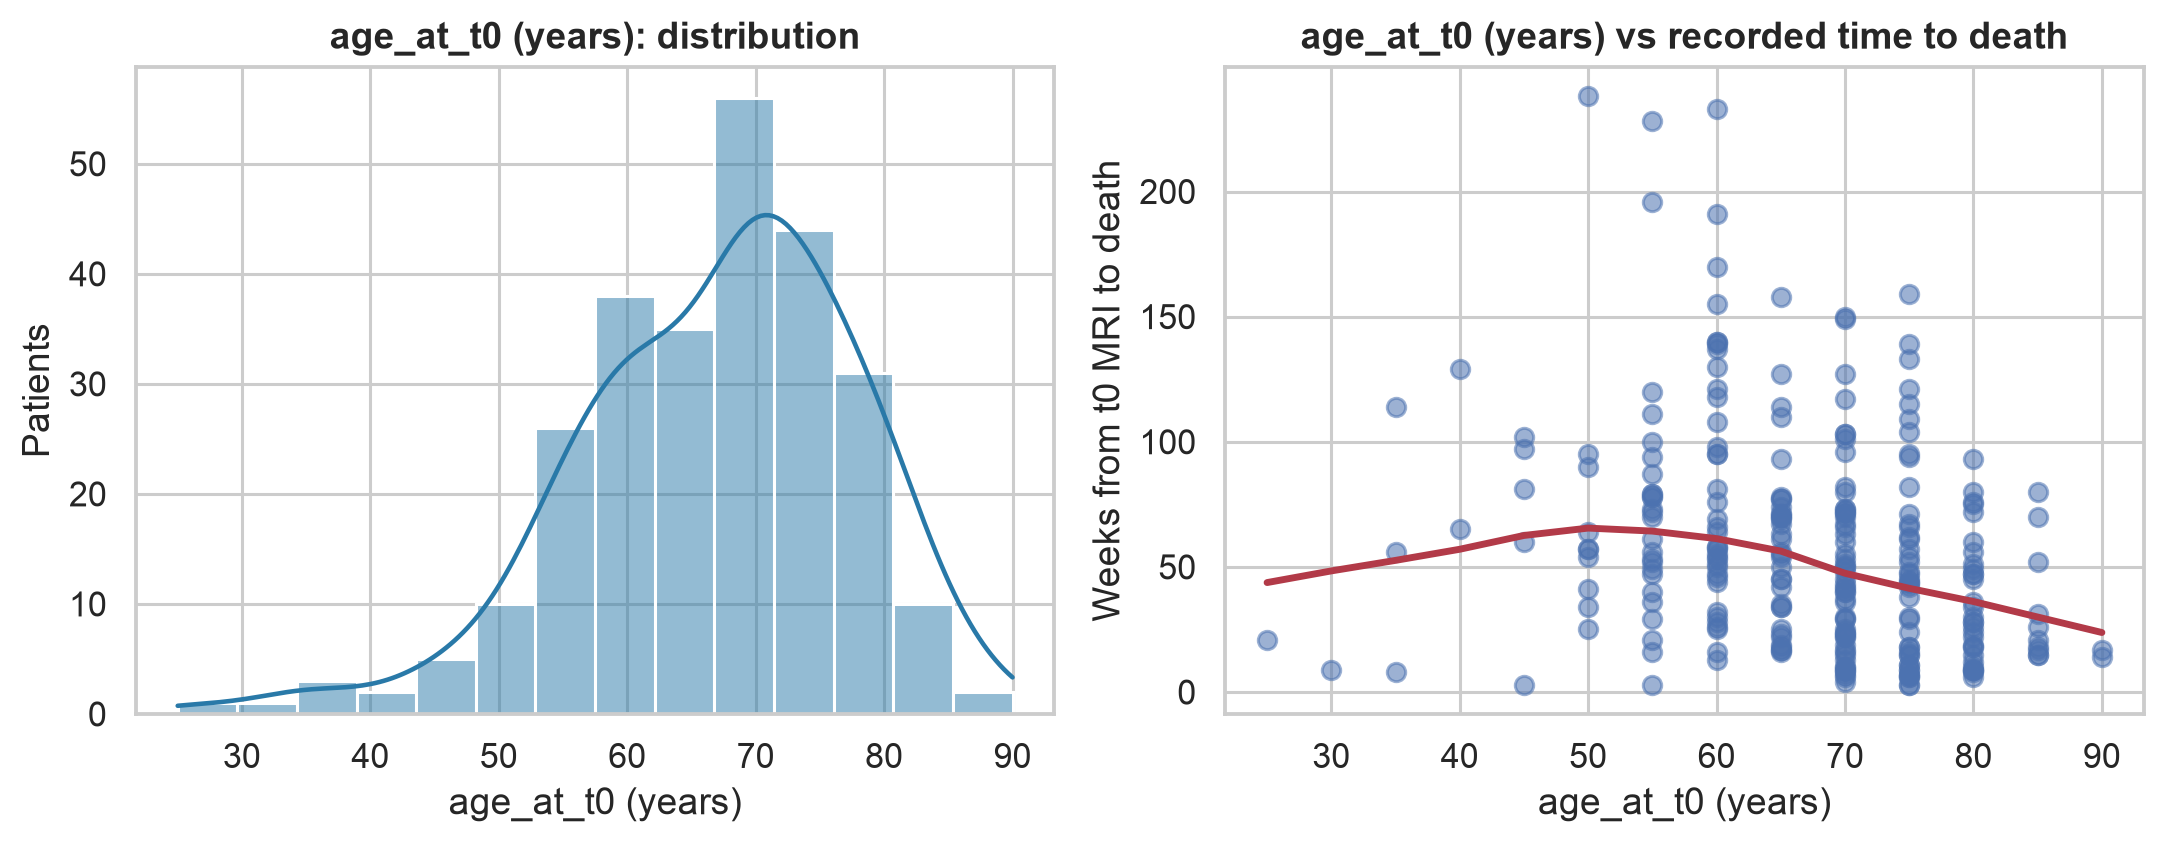

clinical_category_gender.png


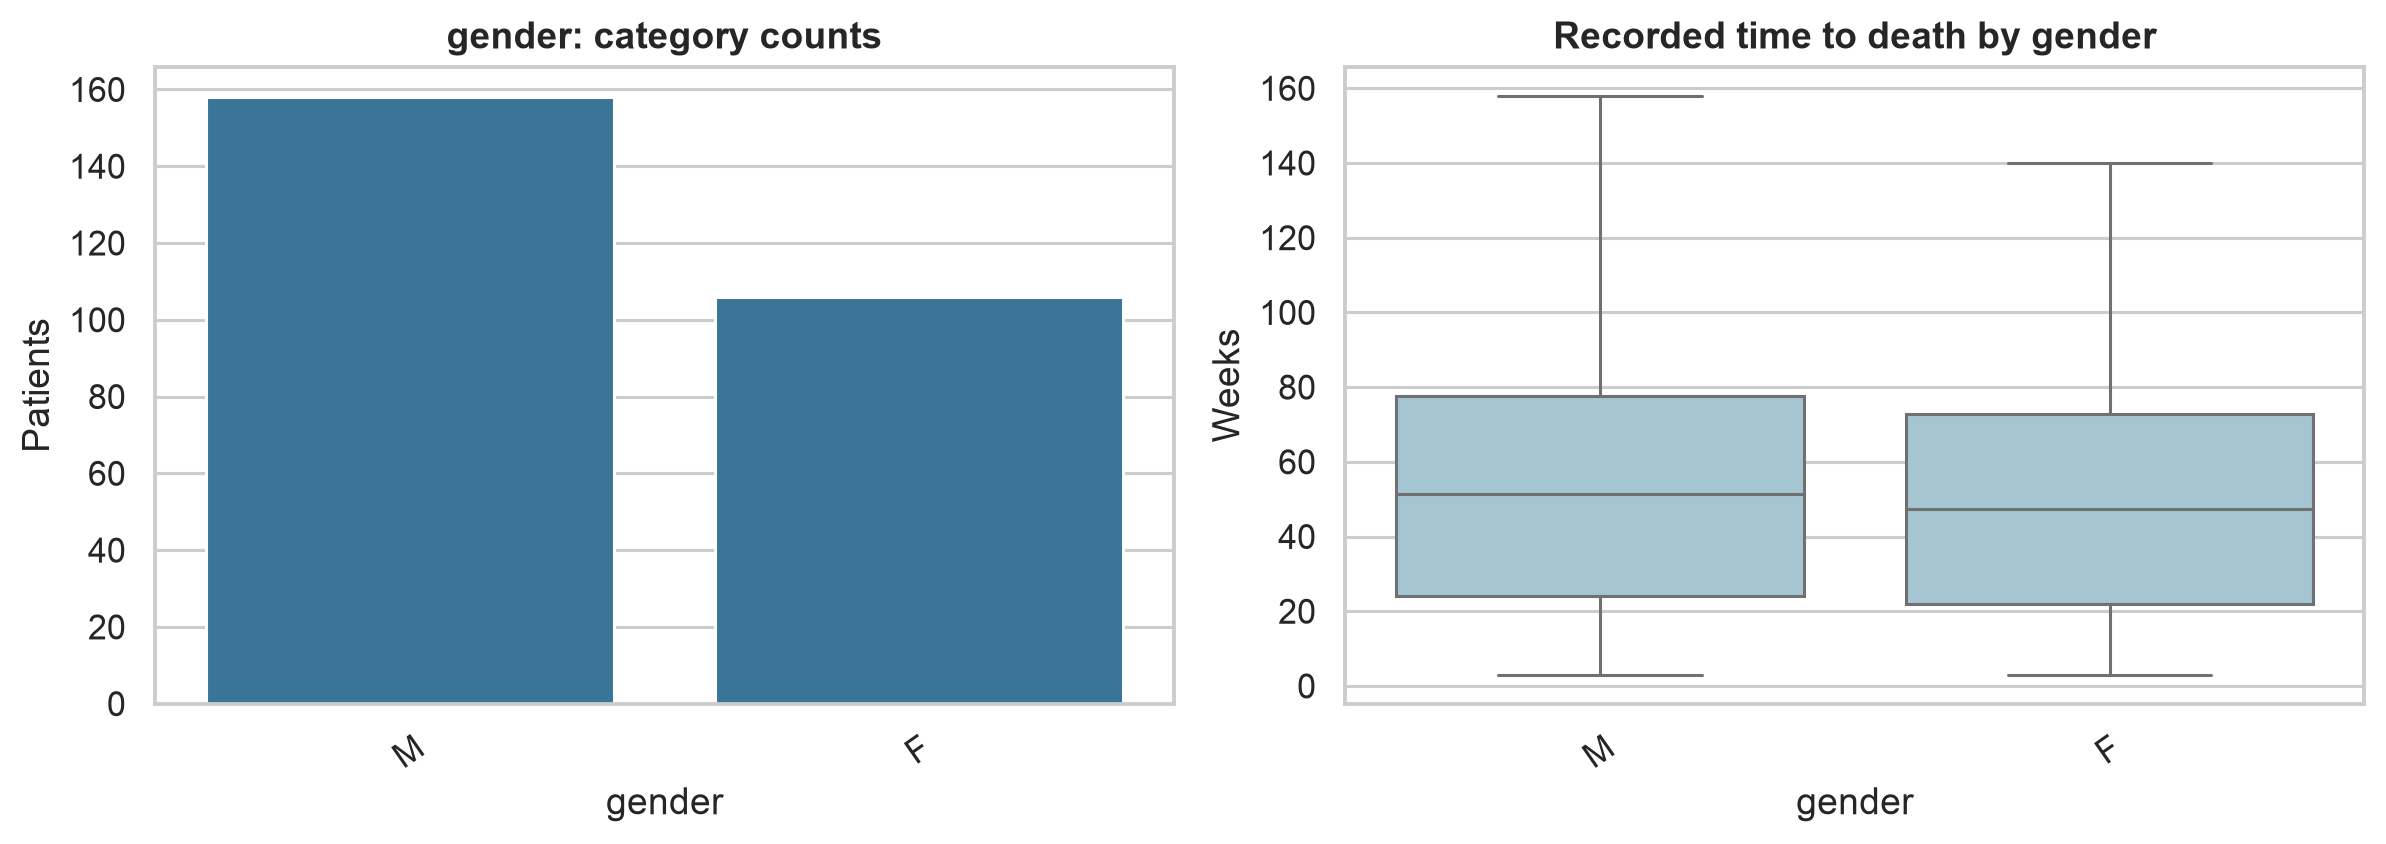

clinical_category_who_guideline.png


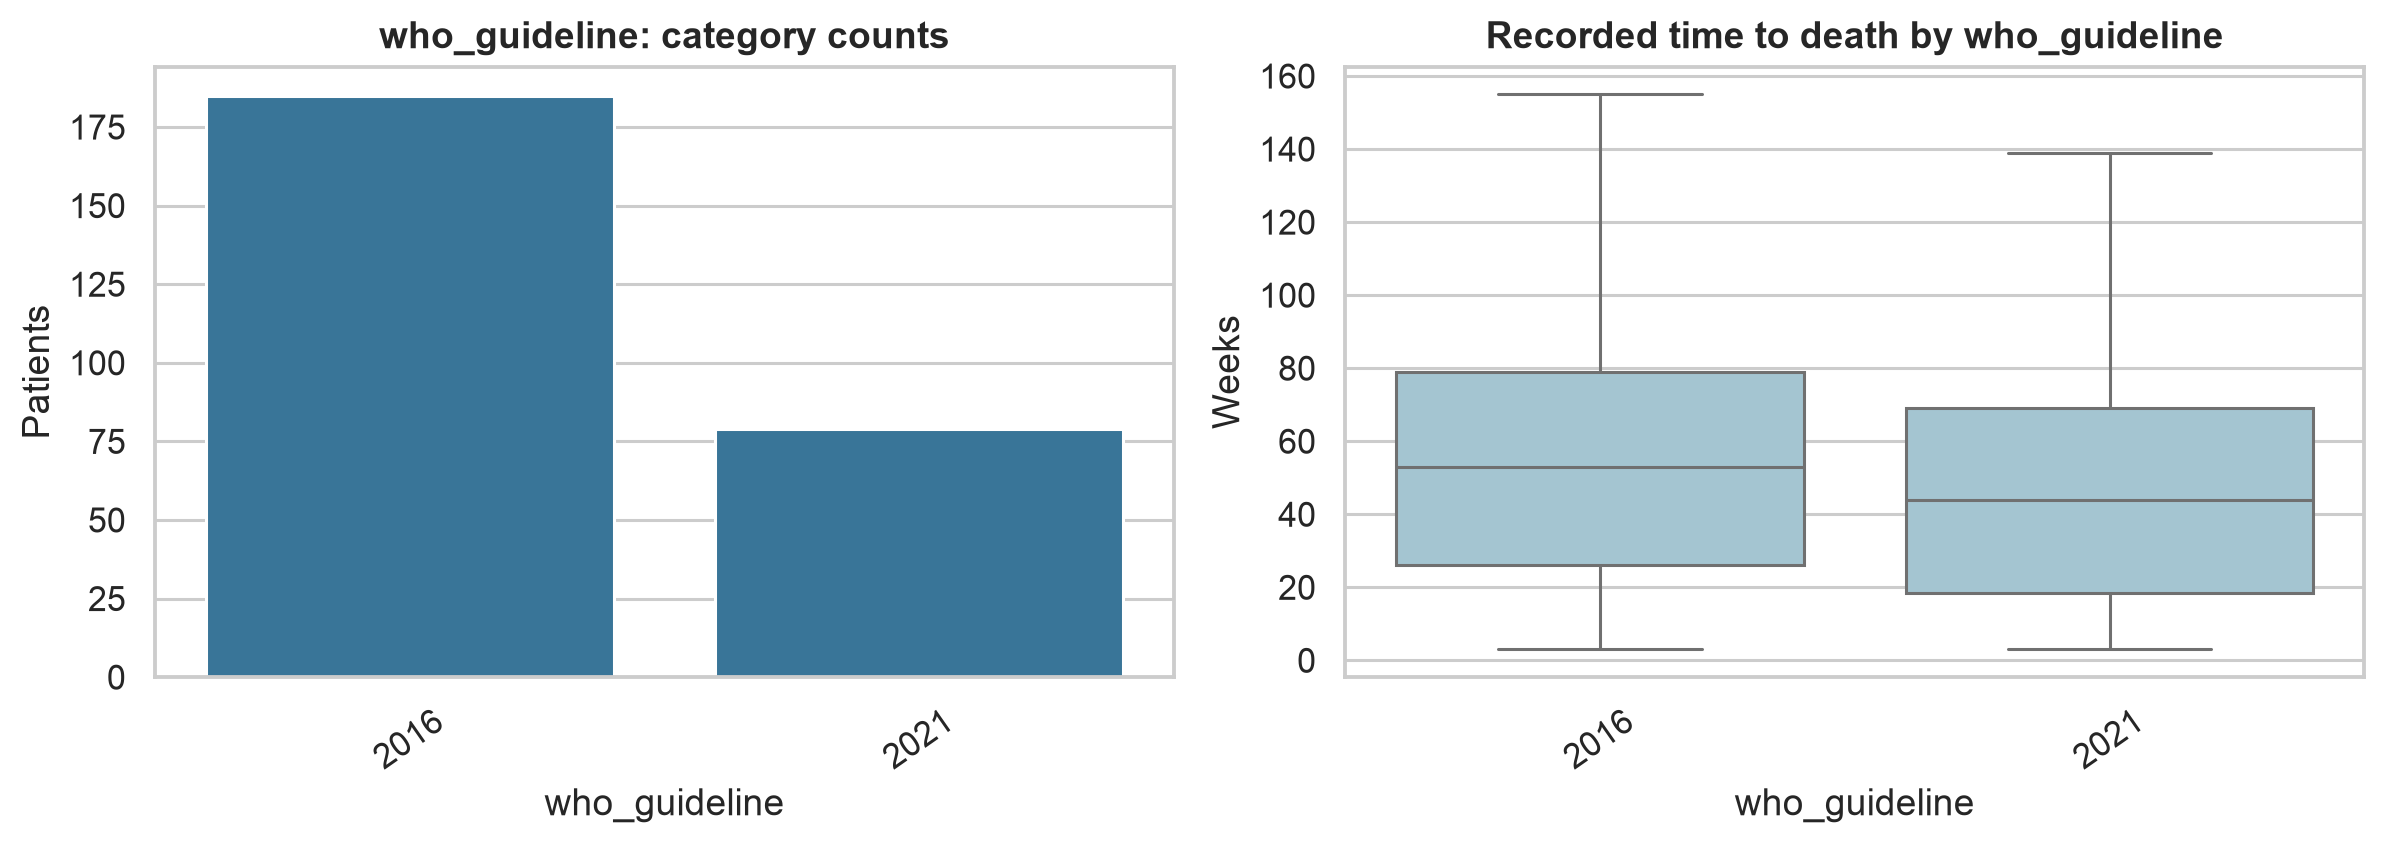

clinical_category_who_performance_status.png


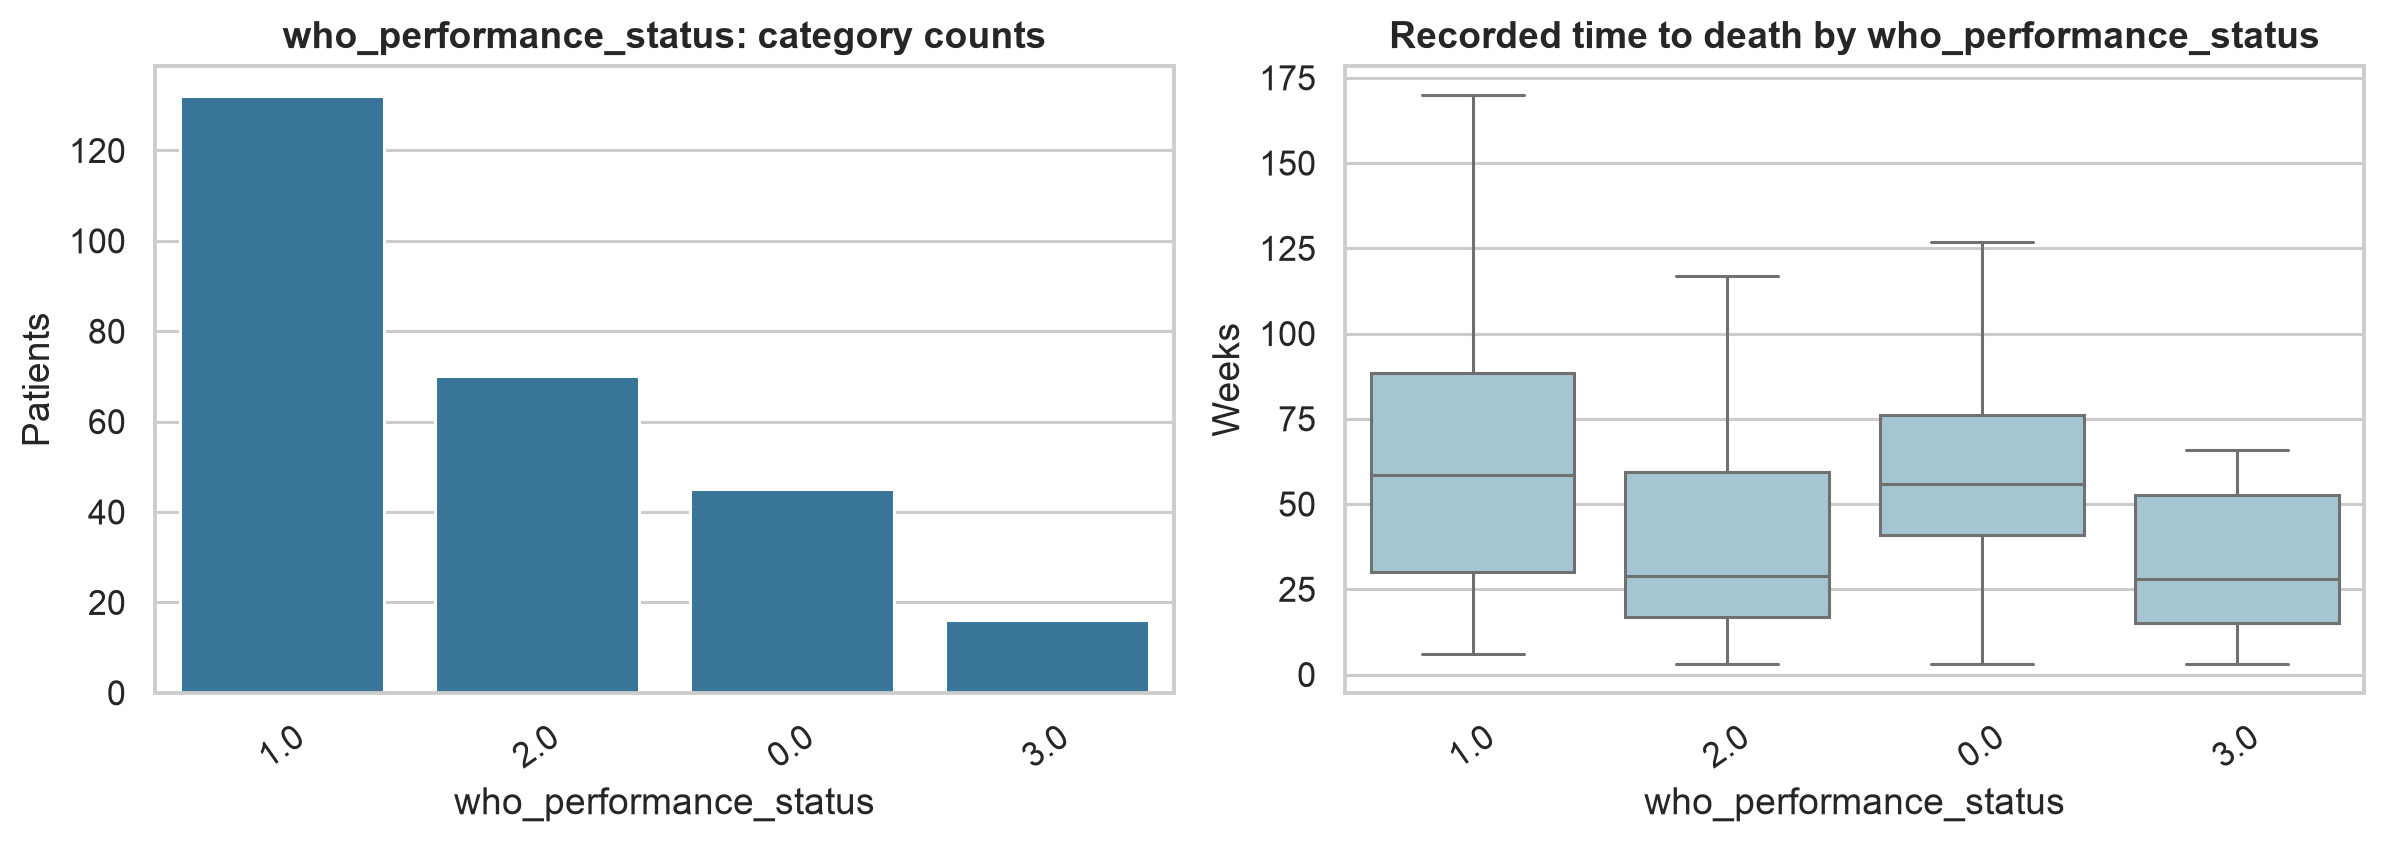

clinical_height_cm.png


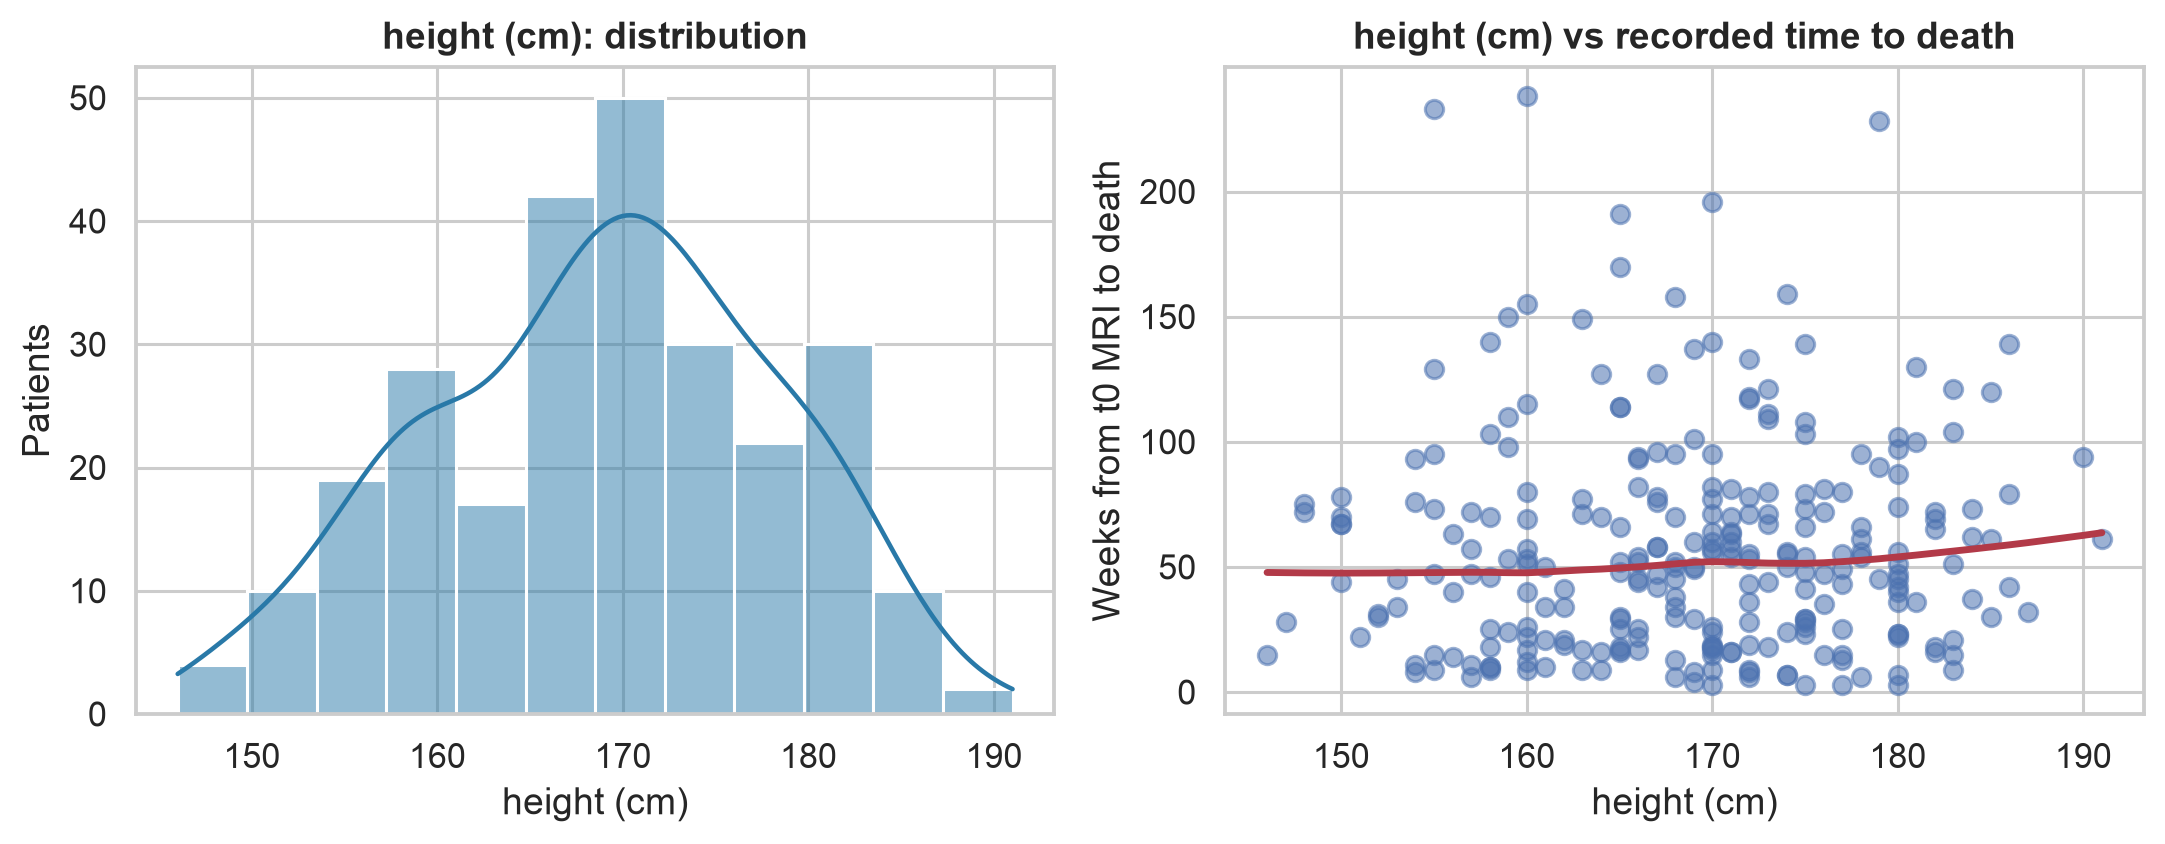

clinical_missingness_heatmap.png


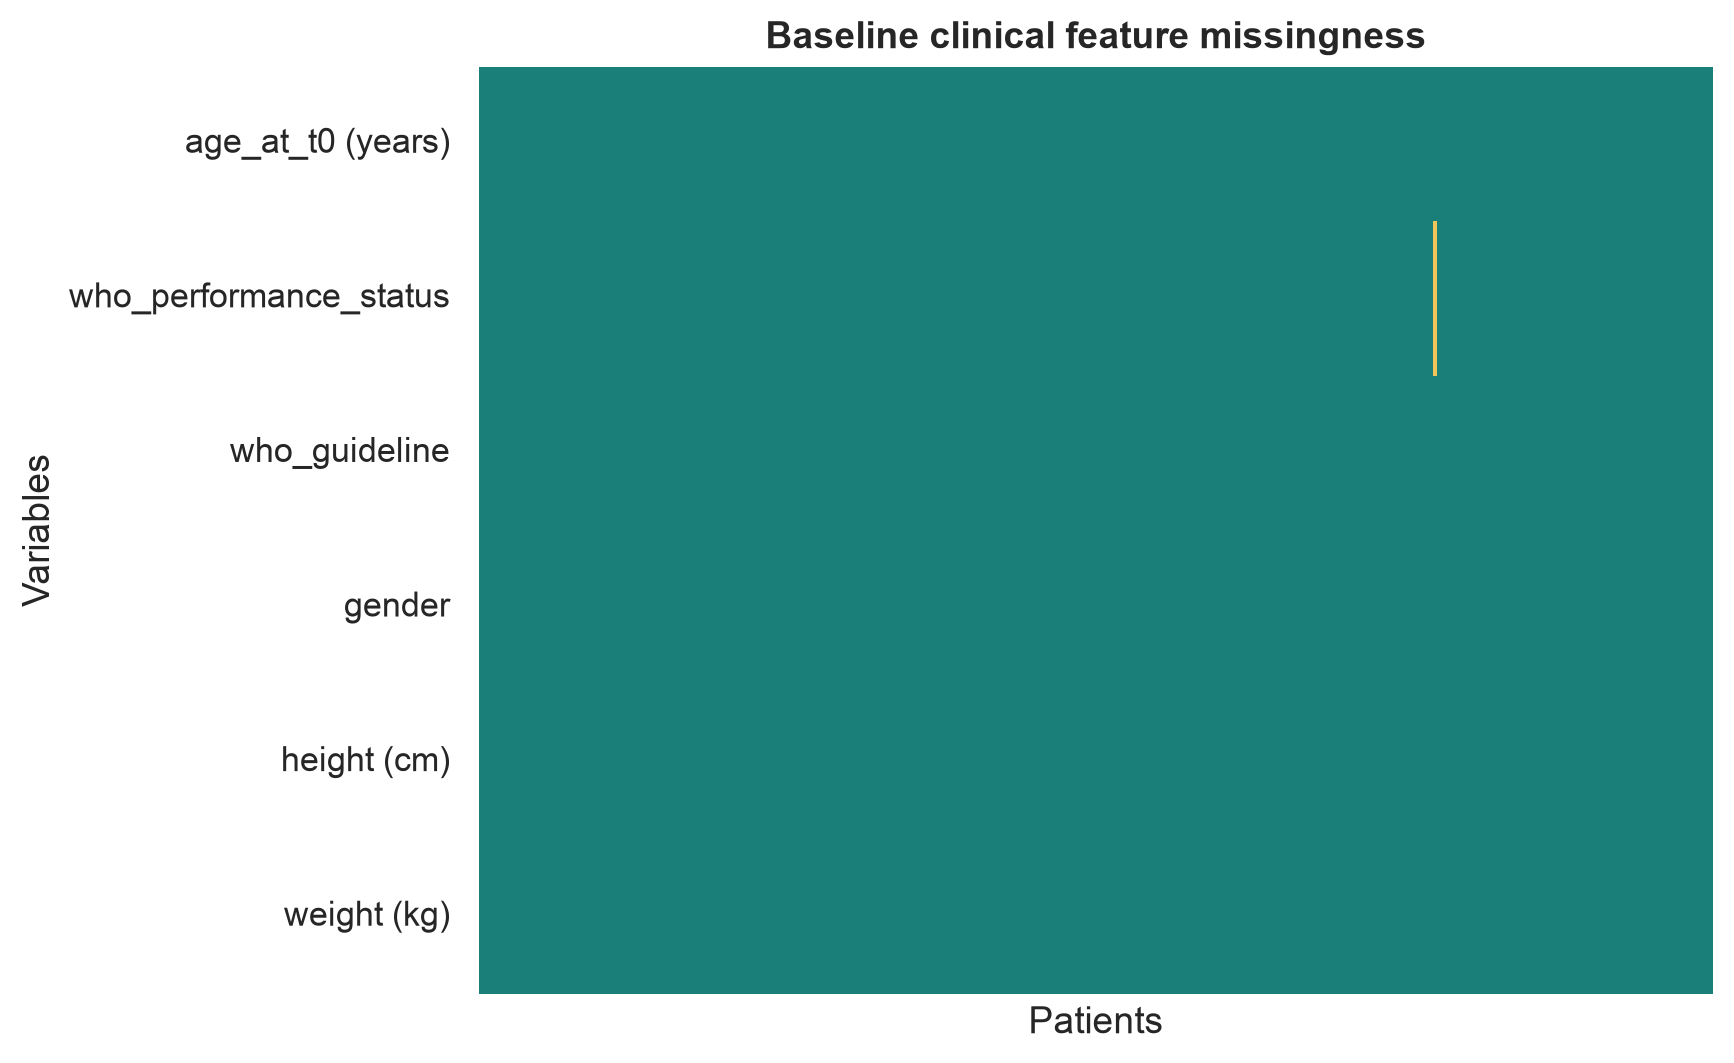

clinical_weight_kg.png


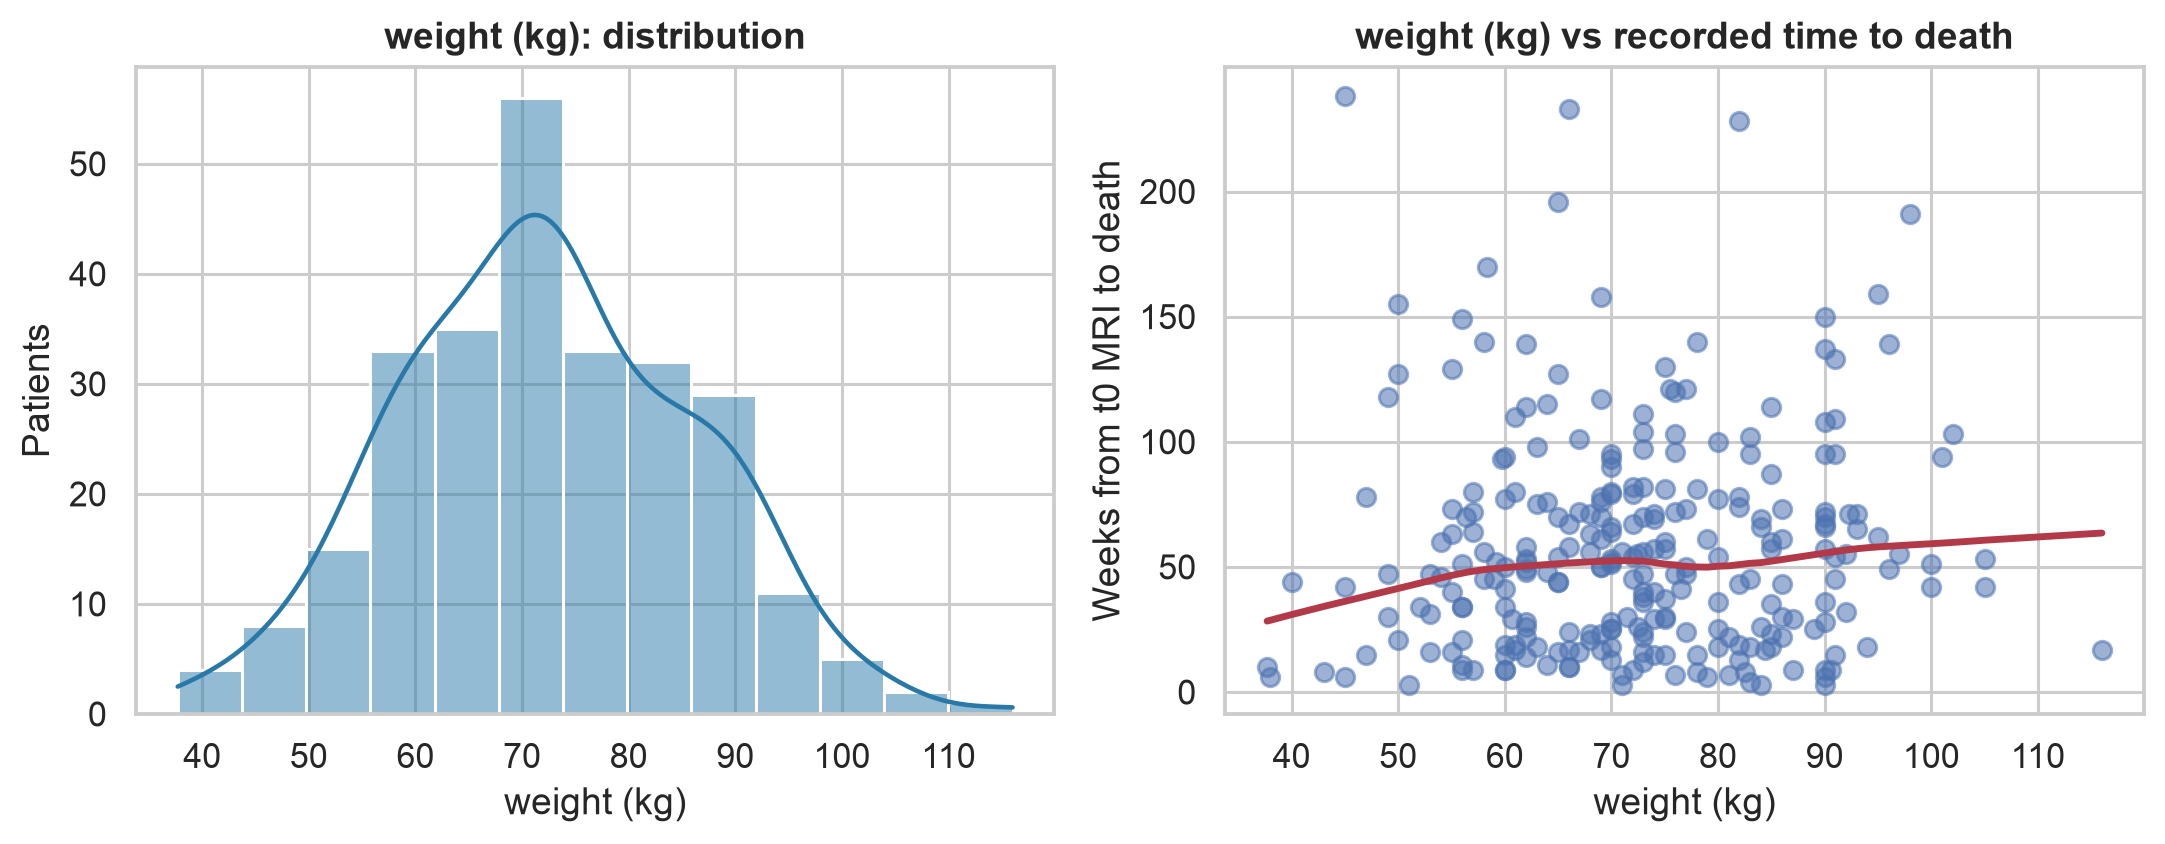

exploratory_association_forest.png


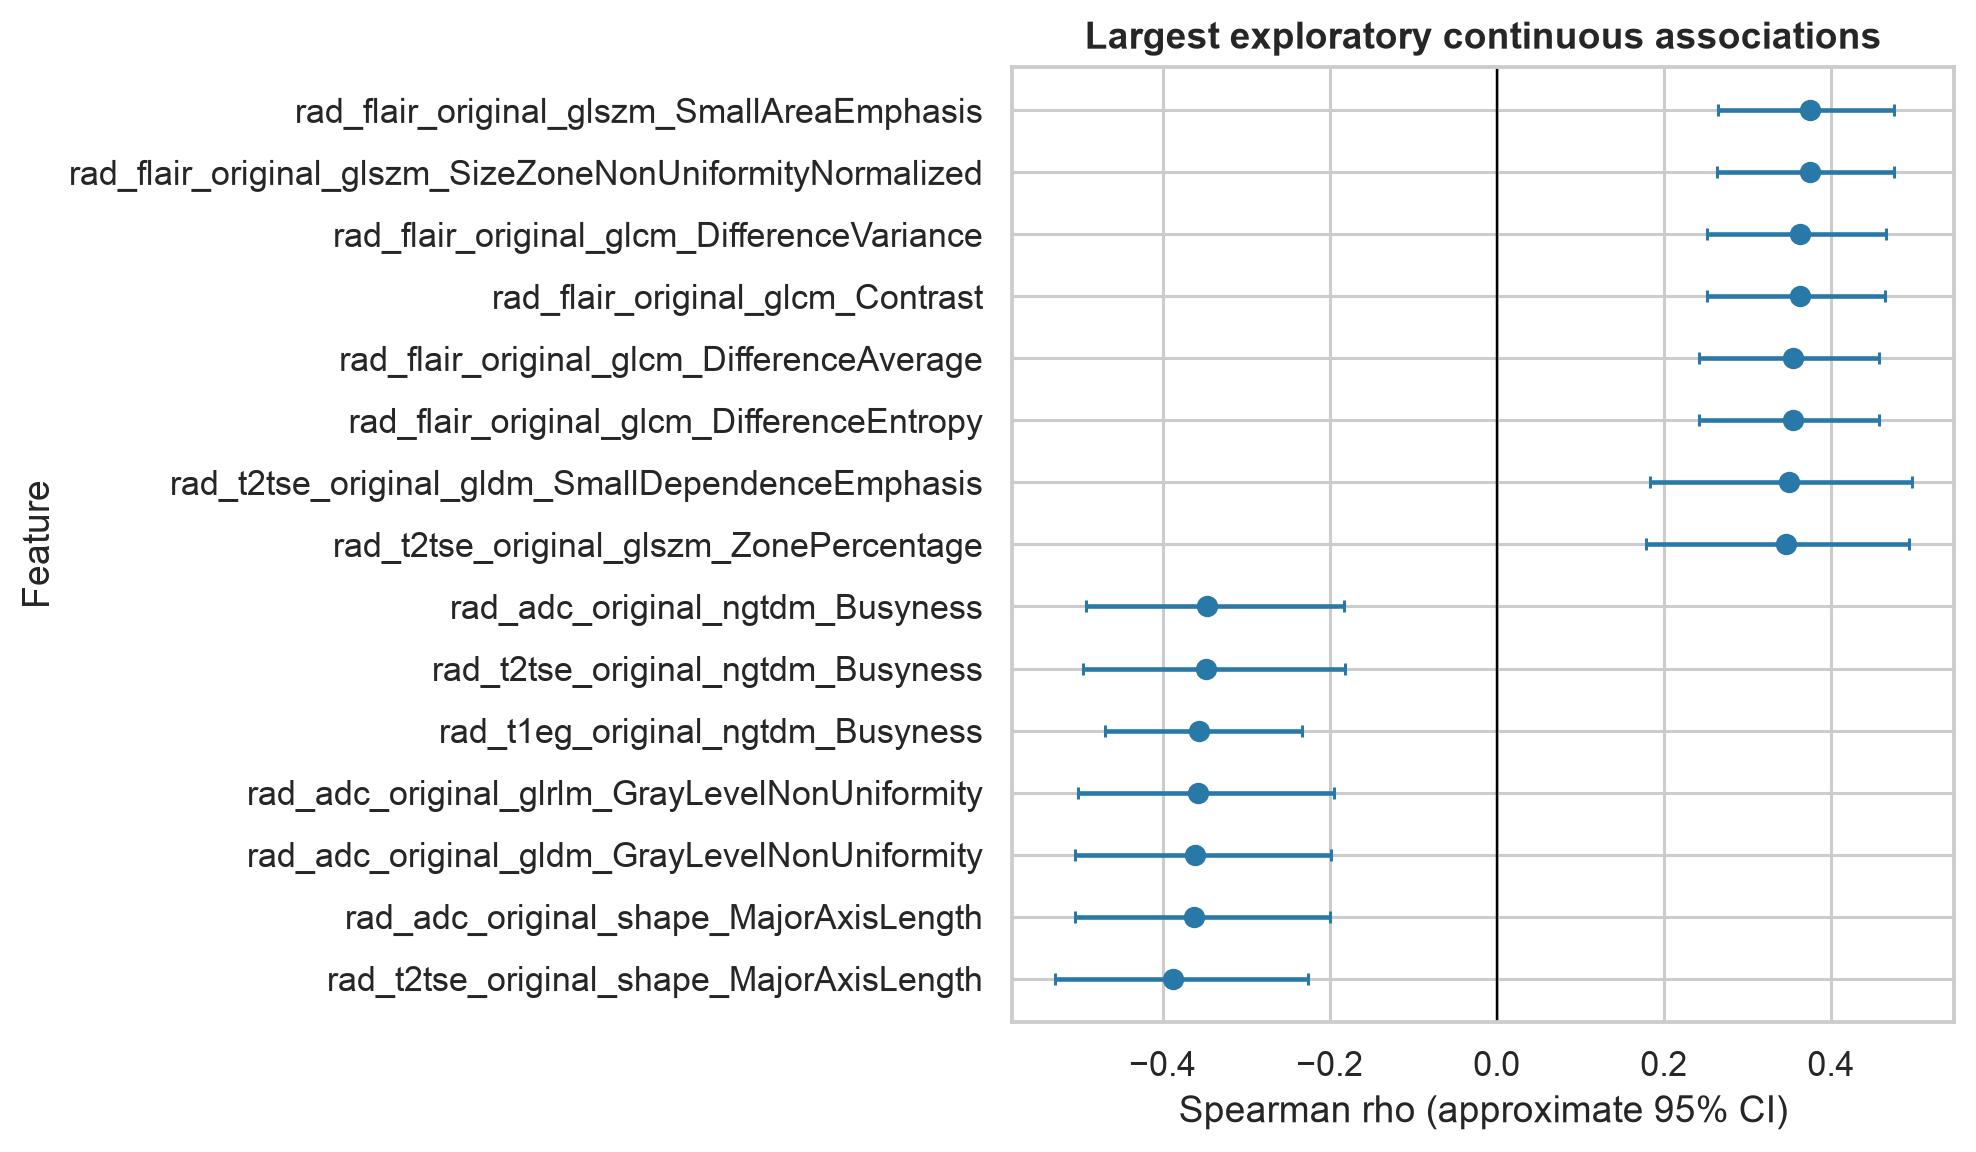

kaplan_meier_event_only_descriptive.png


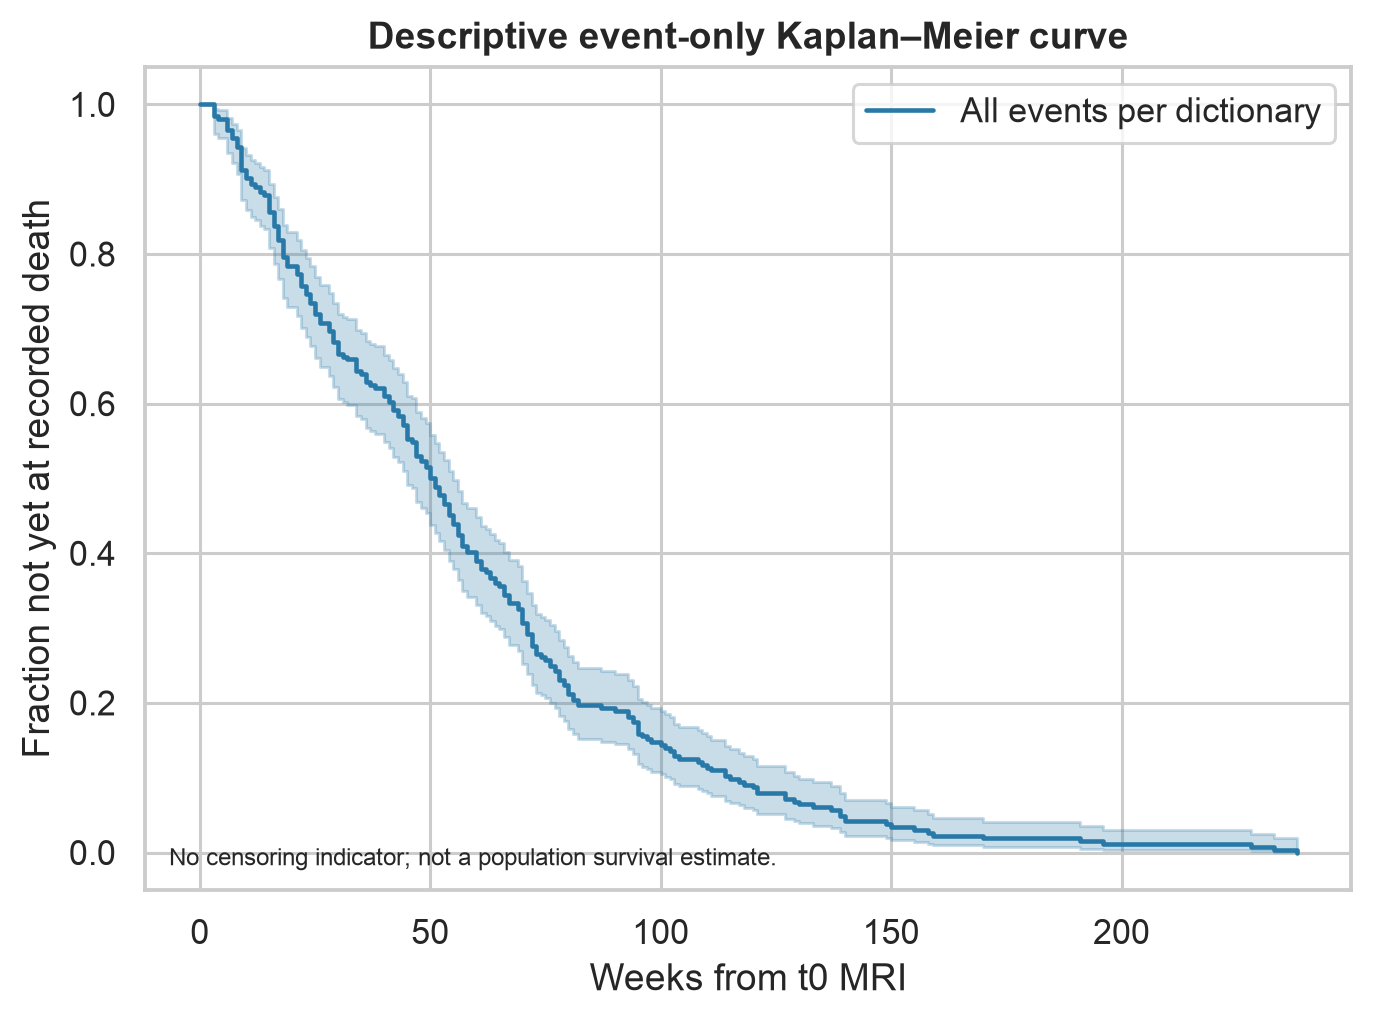

radiomics_correlation_heatmap.png


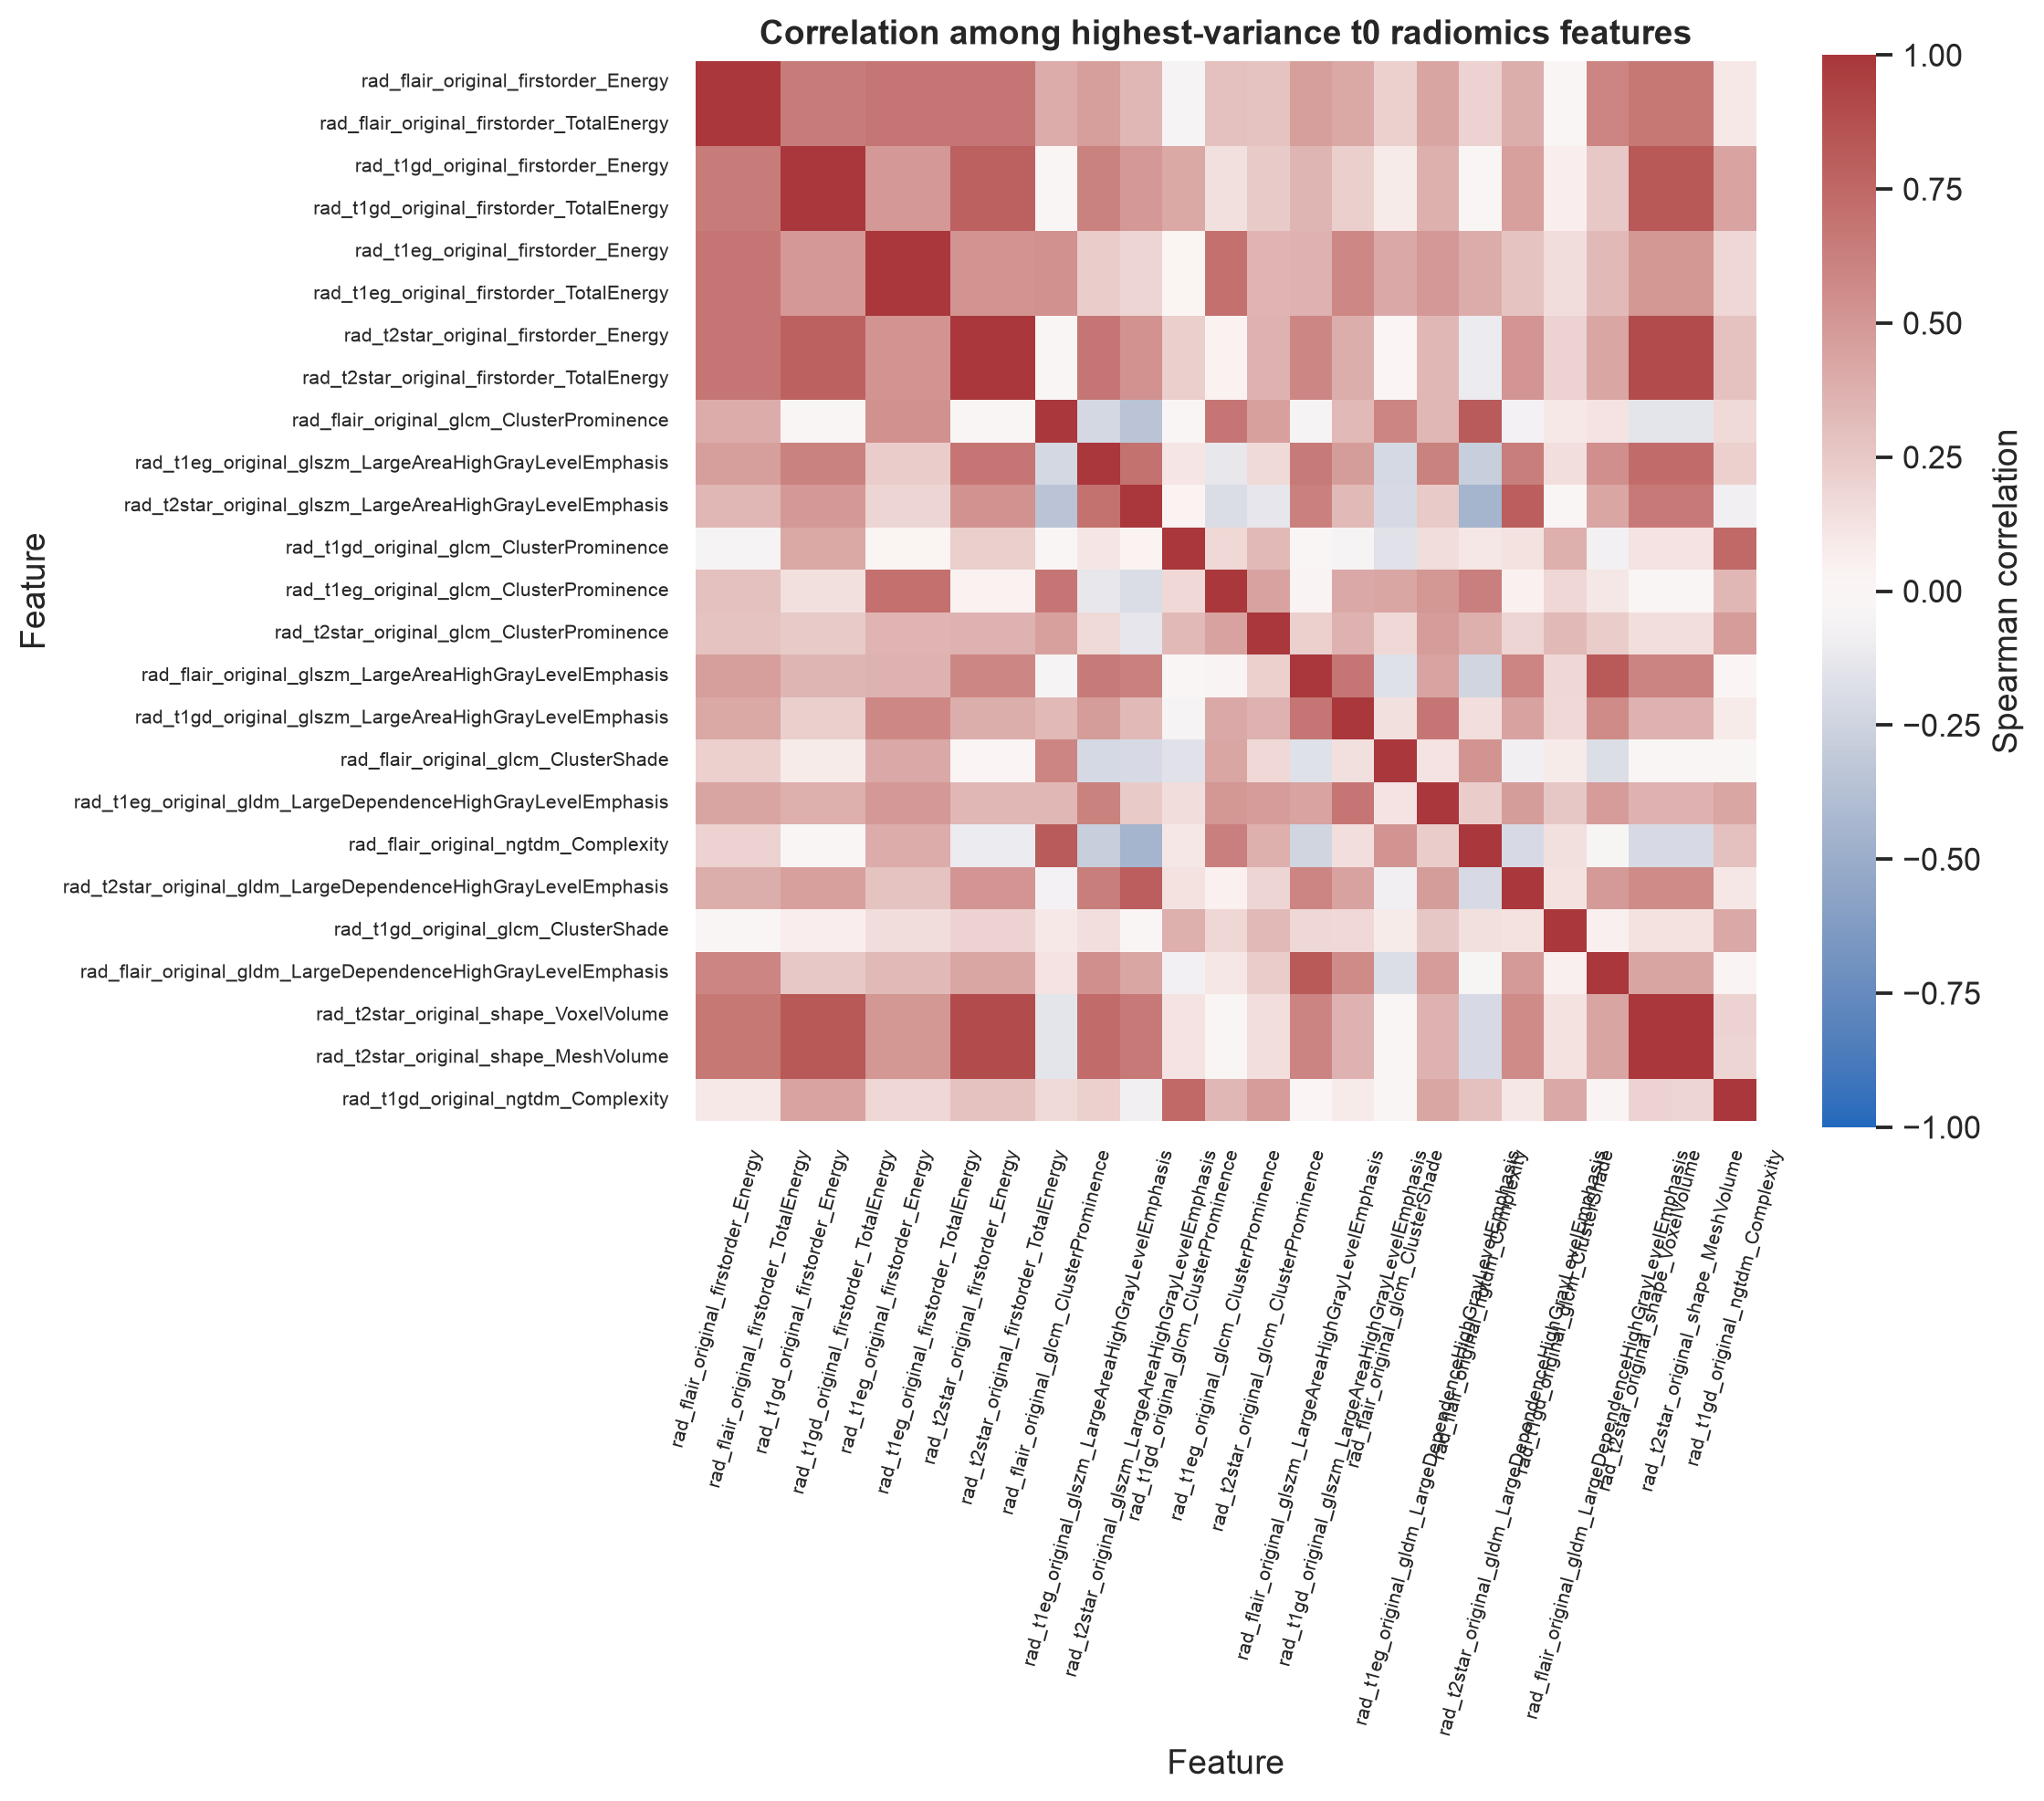

radiomics_feature_family_distributions.png


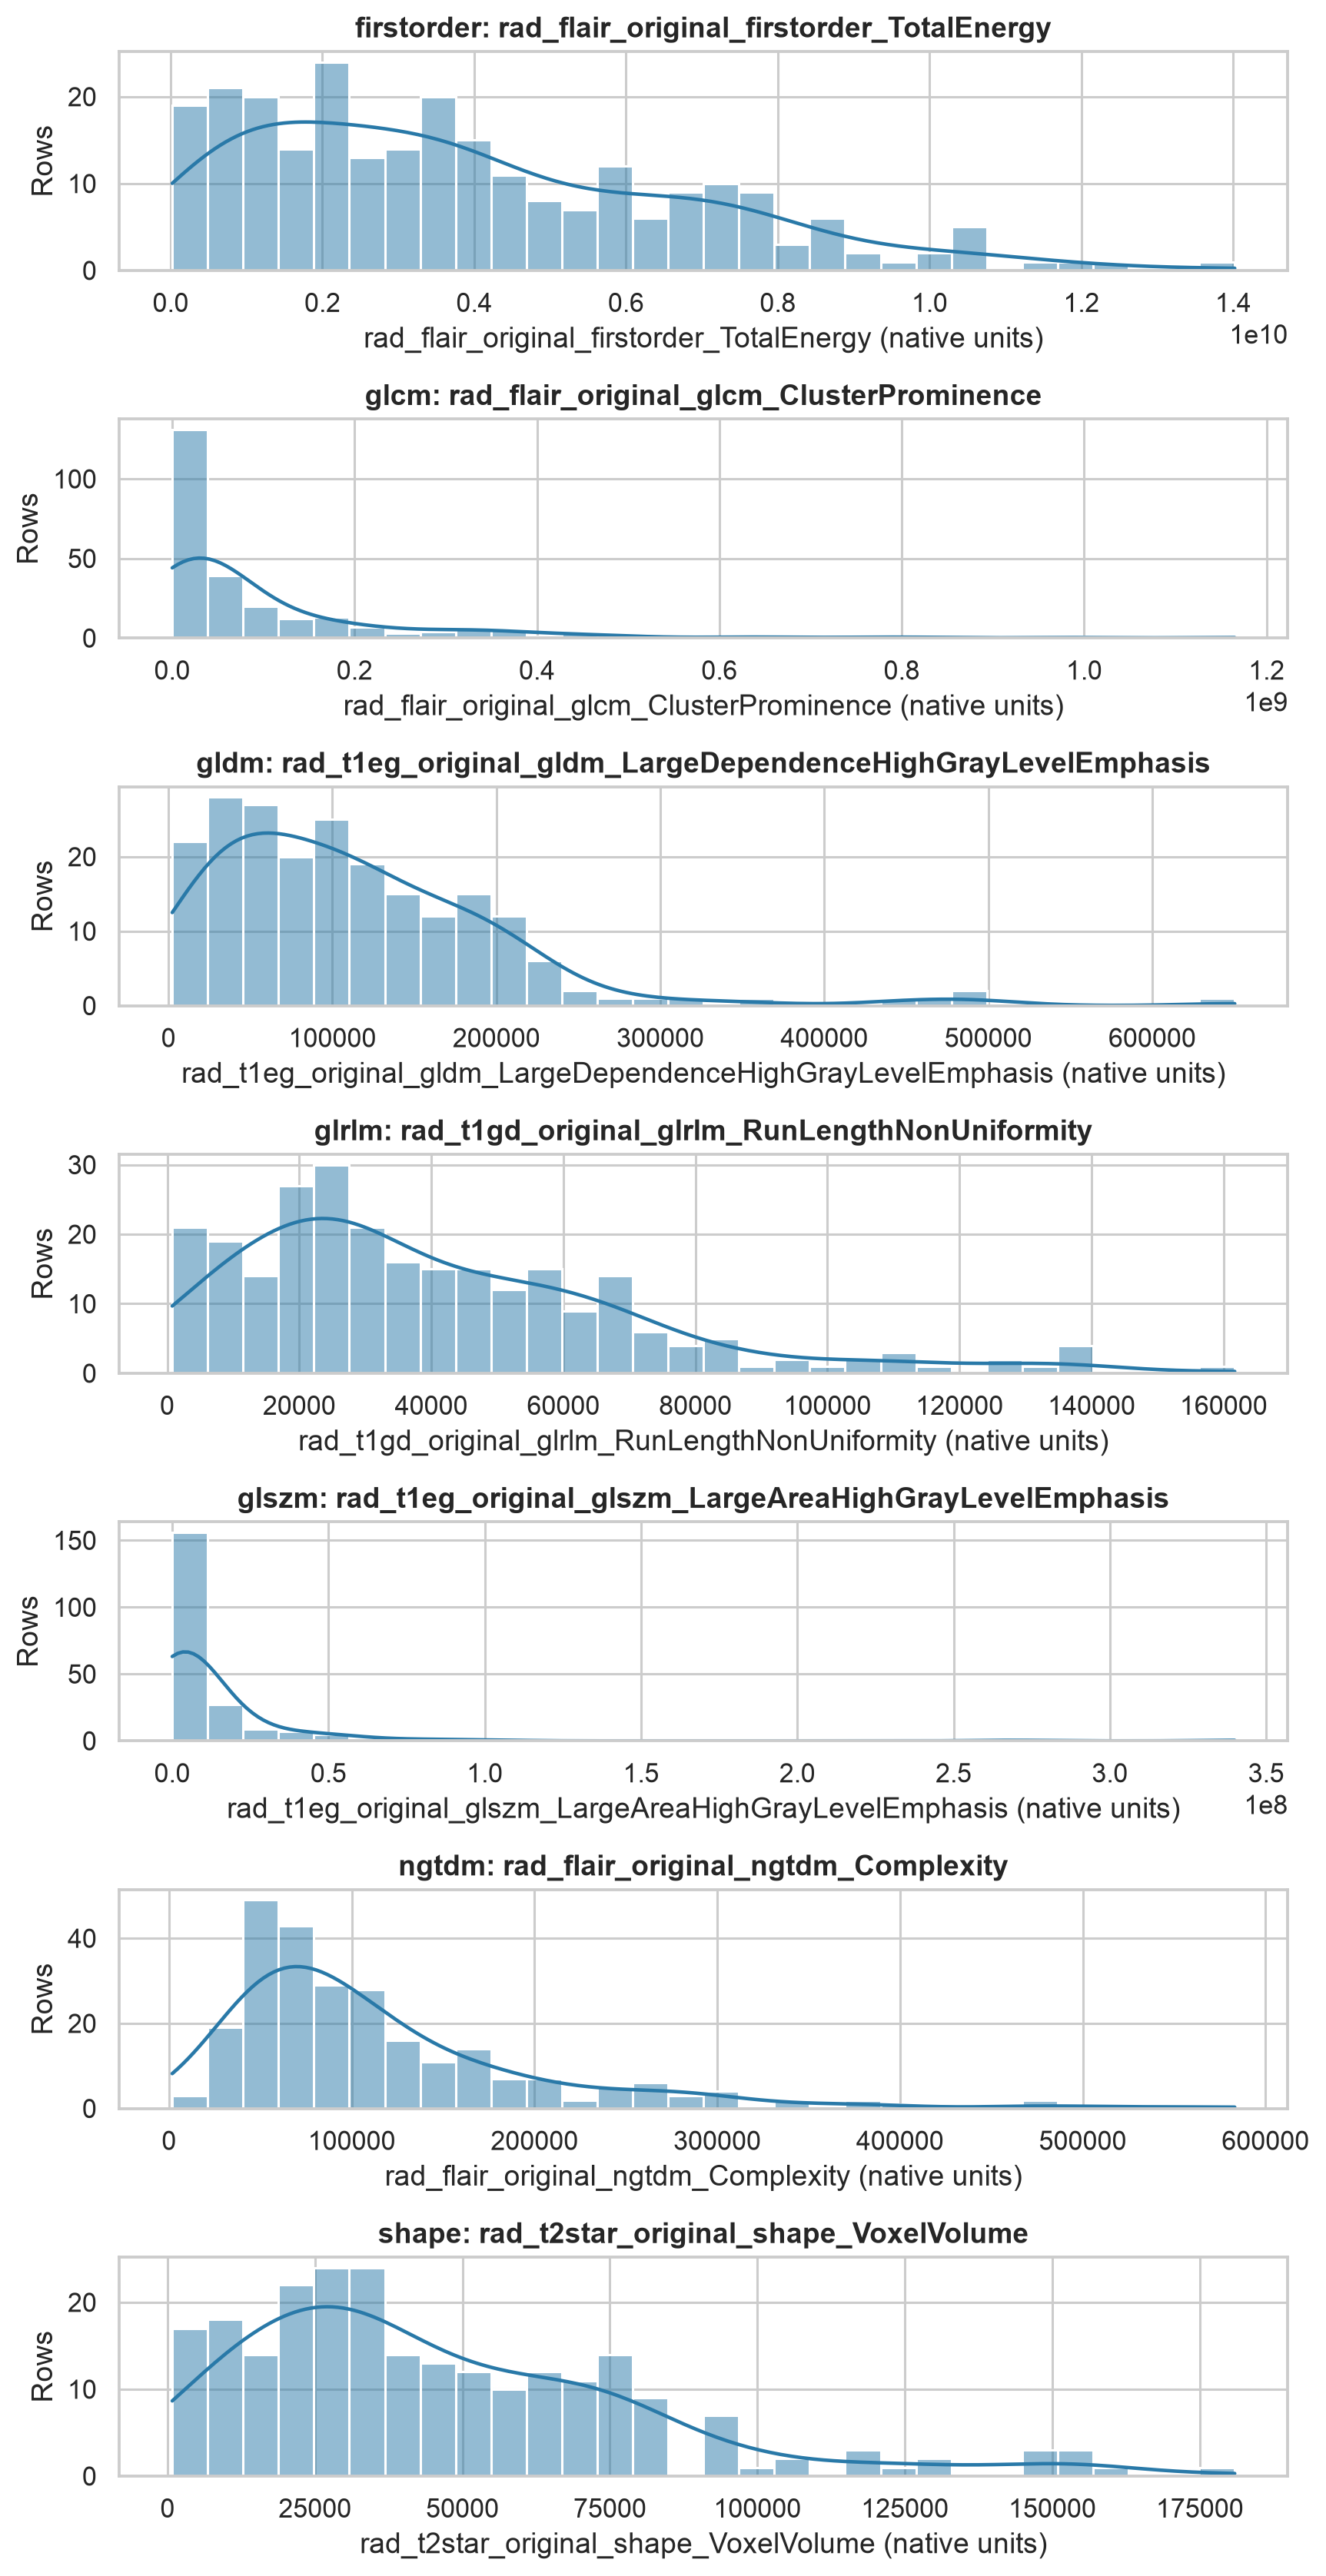

radiomics_pca.png


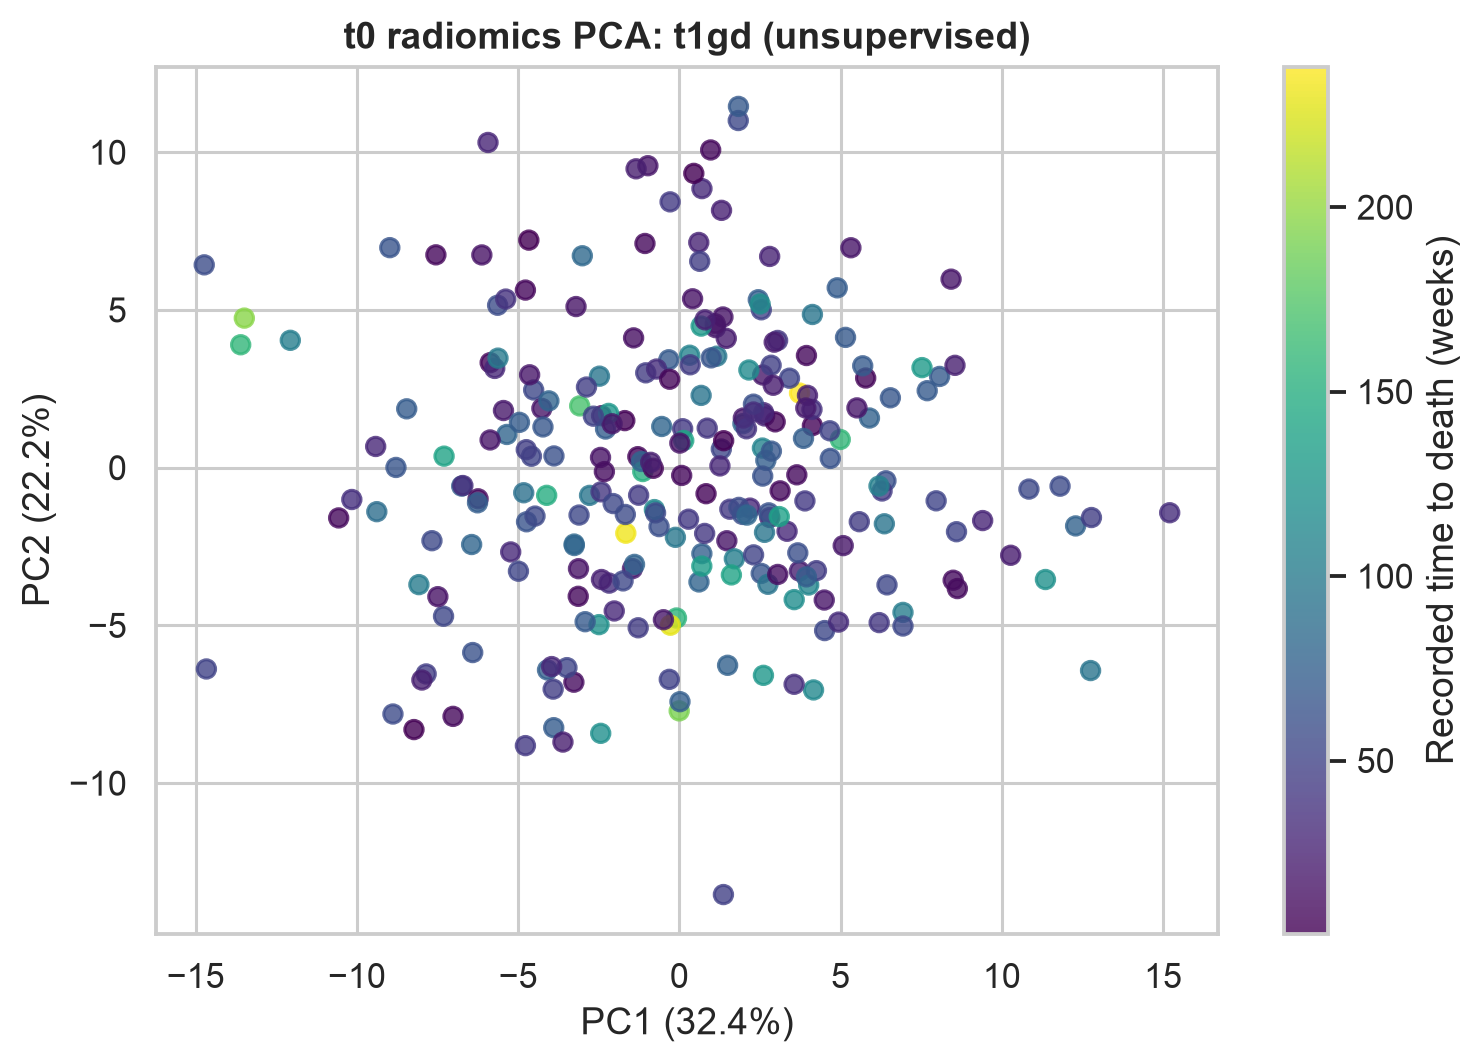

survival_distribution.png


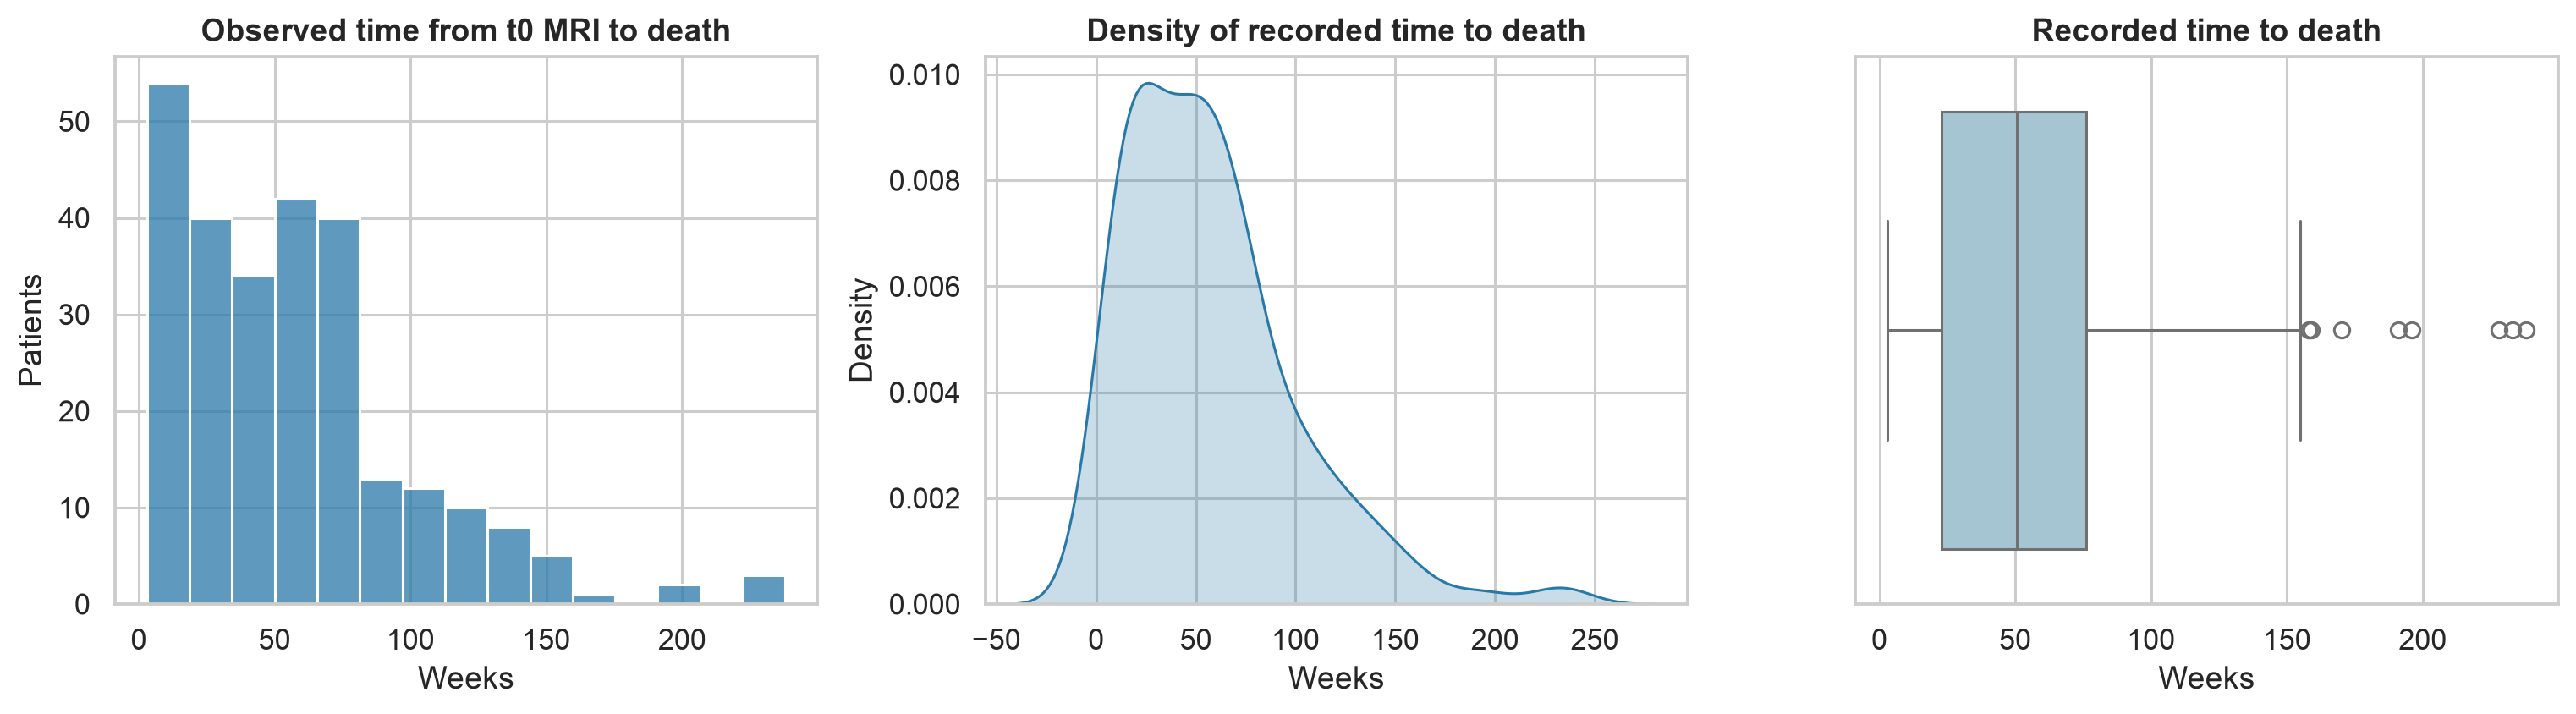

top_candidate_associations.png


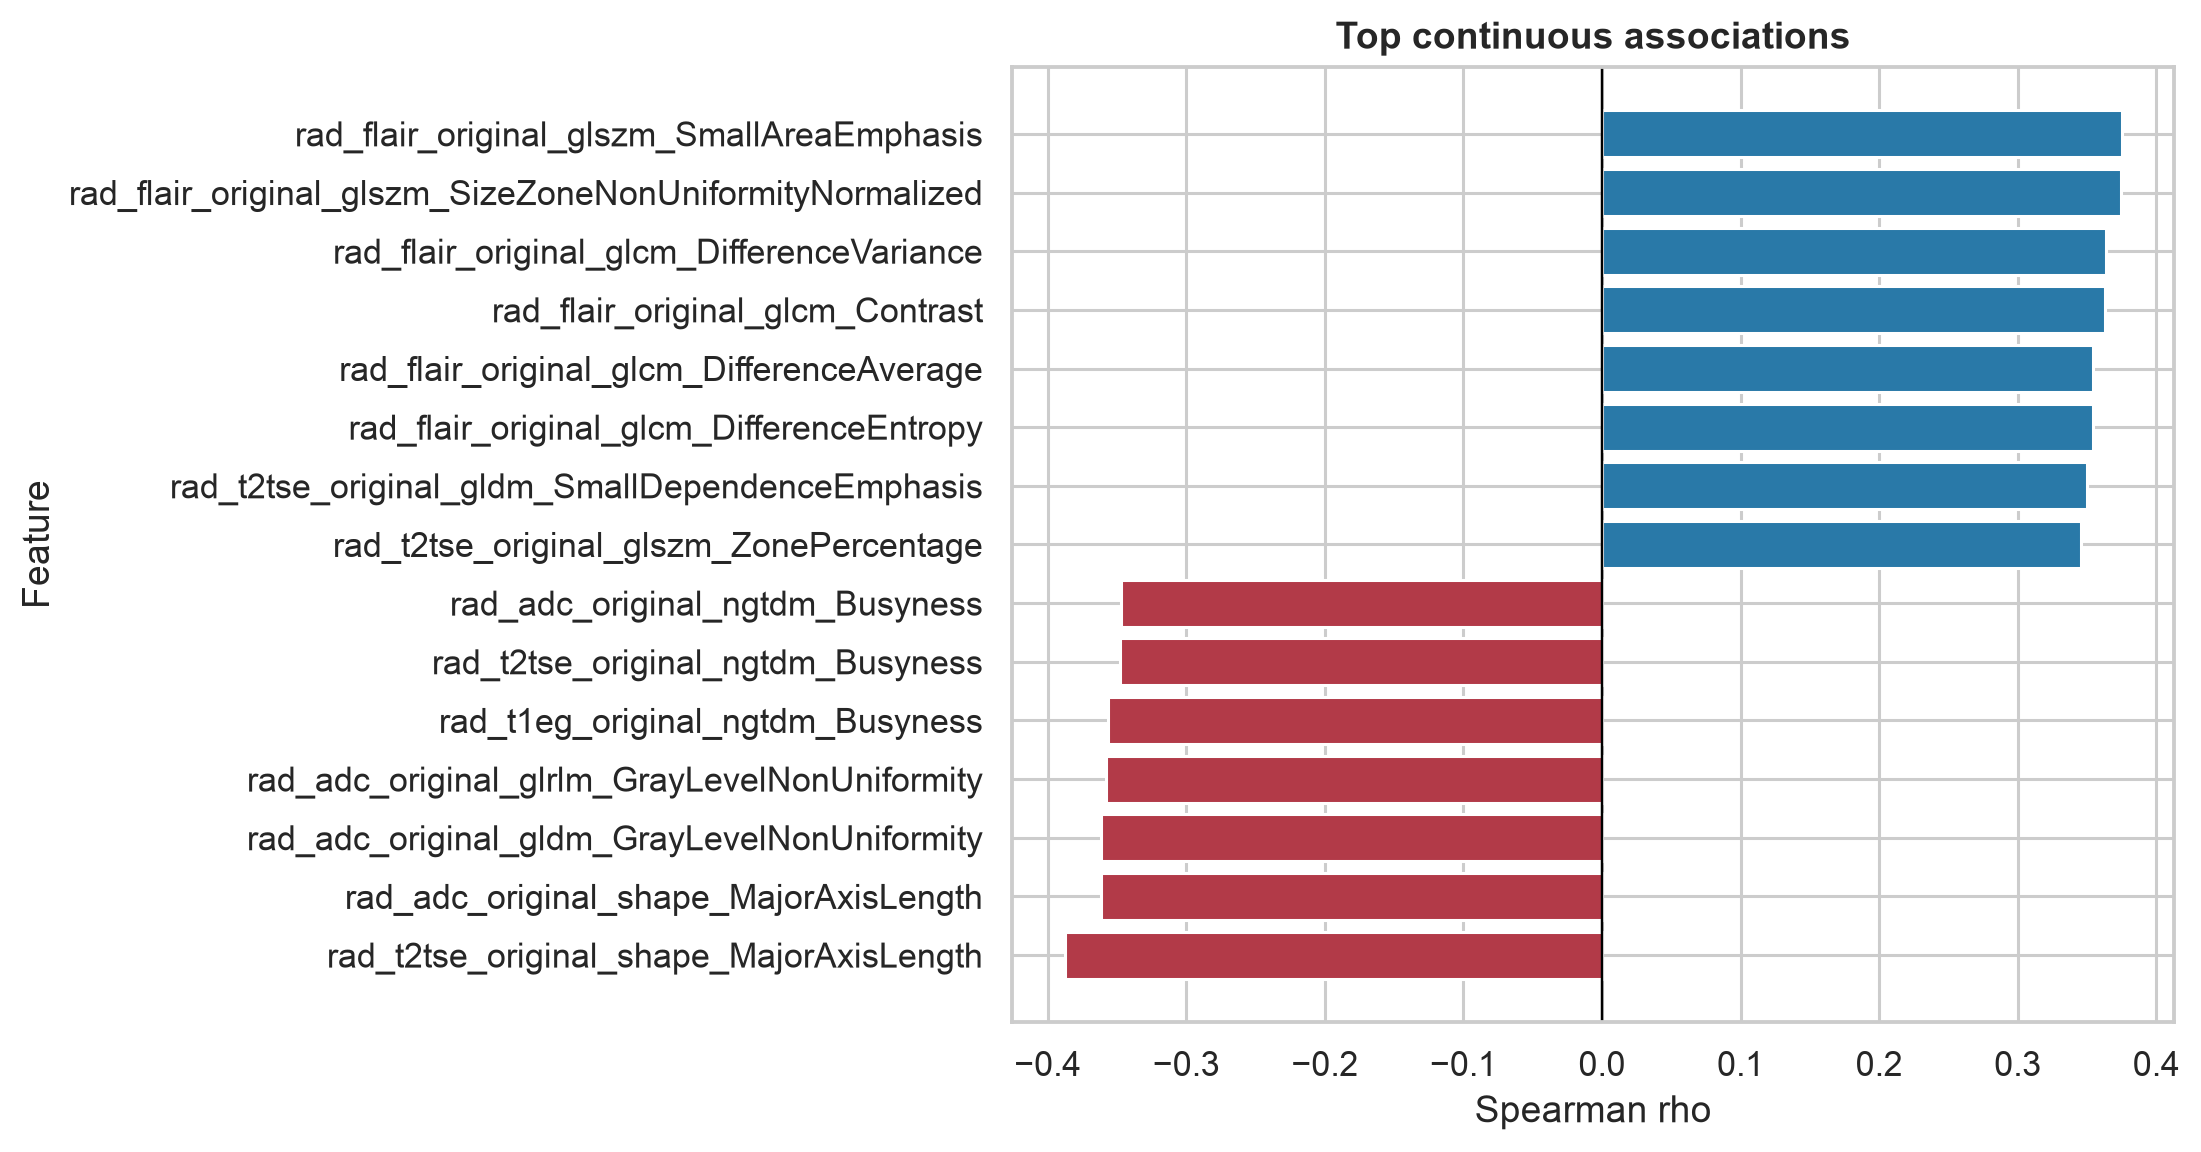

tumor_volume_vs_survival.png


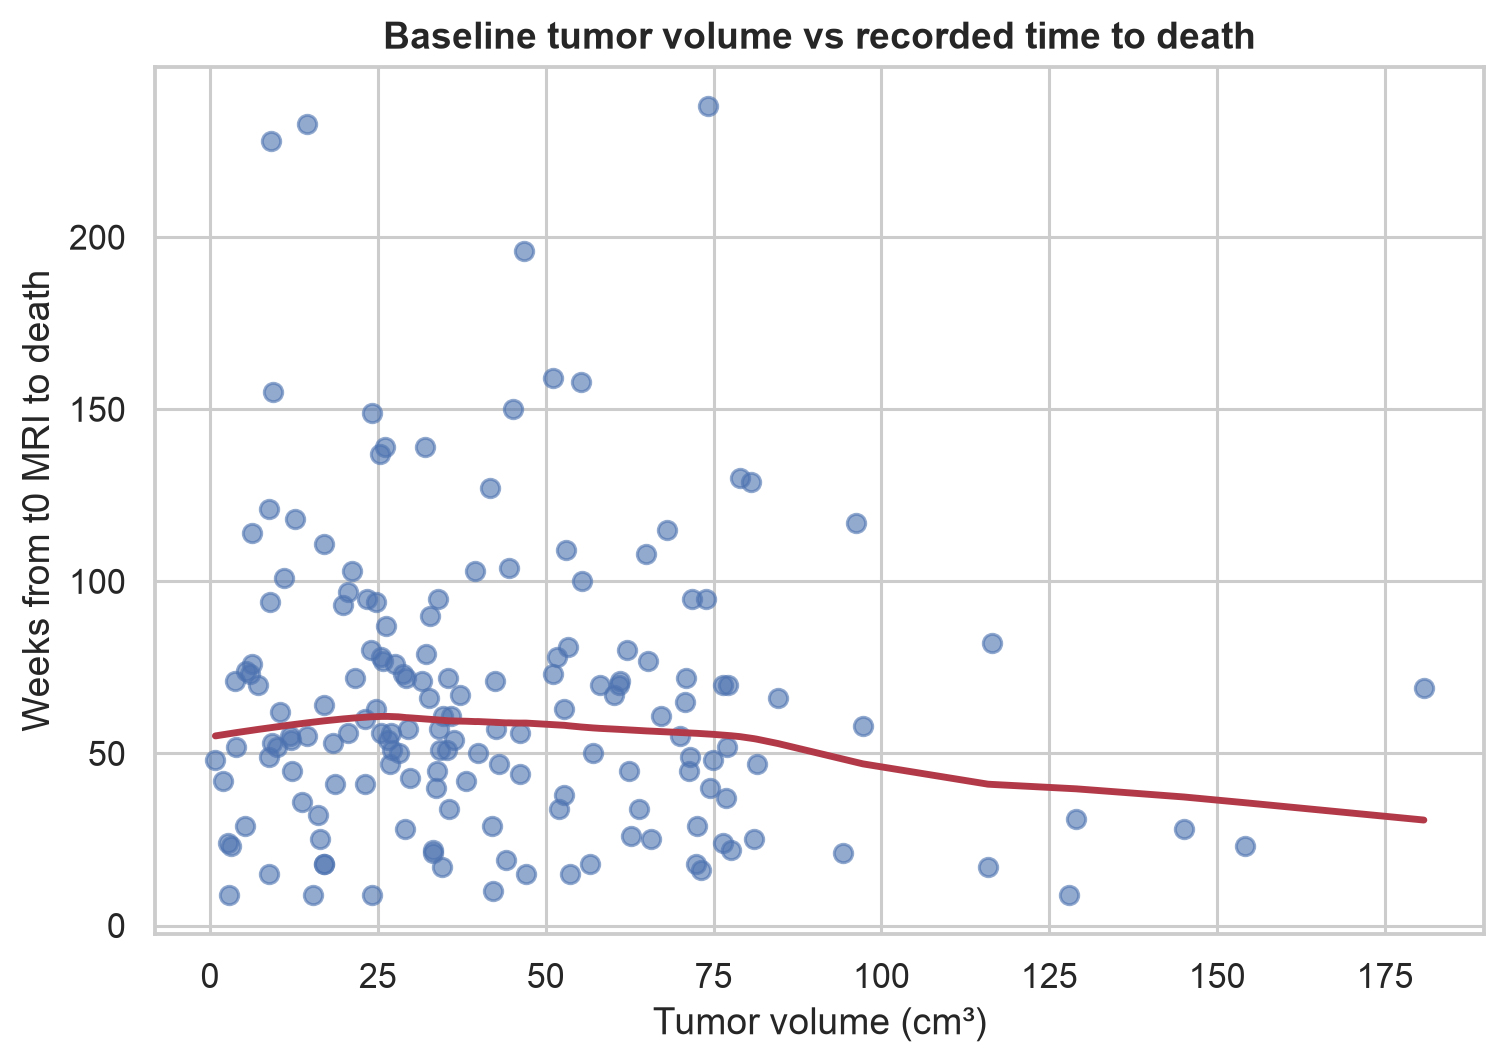

In [23]:
# Display selected exported outputs without patient identifiers.
report_path = OUT_DIR / "eda_report.md"
print(report_path.read_text(encoding="utf-8"))

for table_name in (
    "data_inventory.csv",
    "survival_summary.csv",
    "clinical_numeric_summary.csv",
    "radiomics_feature_family_summary.csv",
    "survival_associations_ranked.csv",
    "feature_availability_and_leakage_audit.csv",
    "longitudinal_feasibility.csv",
):
    table_path = TABLE_DIR / table_name
    if table_path.exists():
        print(f"\n{table_name}")
        table = pd.read_csv(table_path)
        display(table.head(20))

show_modeling_and_leakage_audit()
display_eda_figures()